# Does a Hit Last? Early Signals of Chart Longevity on the Billboard Hot 100
**INFO 2950, Phase 3 (graded draft)**

Data and code: https://github.com/harrylin1015/info2950-chart-longevity

**How this notebook is organized.** We follow the rubric's order: introduction, data description and cleaning, preregistration statements, data analysis, evaluation of significance, conclusions, limitations, and bibliography. Sections that carry over from Phase 2 (the research question, data description, two exploratory figures, the preregistration statements, and the data limitations) keep our Phase 2 text, with changes labeled **Phase 3 change**, **Phase 3 update**, or **added in Phase 3**. Changes that answer a TA comment say **(TA feedback)**. All numbers are updated for our Phase 3 data: Spotify charts for the same years as our Billboard data (TA feedback) and our cleaning fixes.

**New to statistics?** The box **How to read our statistics**, at the start of the Data analysis section, explains every statistical term we use in plain language.

## Introduction

### Why this matters
A song's debut week is loud and hard to read. Streaming lets an artist's fans play a new release thousands of times in its first days, so a song can debut high on the Billboard Hot 100 and be gone a few weeks later. Other songs debut quietly and stay for half a year. The difference matters to the people who decide where money and attention go after release week: labels choose which songs to push to radio and fund with marketing, playlist curators choose which songs stay on high-traffic playlists, and artists choose which song to follow up with. Each choice is made early, usually within the first two weeks, before anyone knows how long the song will last.

Chart longevity has been studied for decades. Bradlow and Fader (2001) modeled the "lifetime" of Hot 100 songs, meaning how long each song lasts before it leaves the chart. Pessa et al. (2026) show that songs usually chart in one unbroken run and that collective attention to songs fades faster than attention to albums. Success in cultural markets is also notoriously hard to predict ahead of time (Salganik, Dodds and Watts, 2006). Our project asks a narrower, practical question: once a song has debuted, how much do its first two weeks tell us?

### Key terms
- **EDA (exploratory data analysis)**: our first look at the data, using summary numbers and charts before any formal tests.
- **Billboard Hot 100**: the weekly ranking of the 100 most popular songs in the US. It combines streaming, sales, and radio play, with data from Luminate.
- **Run length**: the total weeks a song spends on the Hot 100. We call a run of 20 or more weeks a **long run**.
- **Recurrent rule**: Billboard removes older songs that have fallen down the chart. Since October 2025, a song is removed if it ranks below No. 50 after 20 weeks, below No. 25 after 26 weeks, below No. 10 after 52 weeks, or below No. 5 after 78 weeks (Thompson, 2025). Before that, only the 20-week (below No. 50) and 52-week (below No. 25) cutoffs applied. Because of this rule, 20 weeks is a natural line between a long run and a shorter one.
- **Album track**: a song whose lead artist debuted 3 or more songs on the Hot 100 the same week, which usually means an album came out.
- **Established artist**: the lead artist had a Hot 100 entry in the 3 years before the song's debut.
- **Front-loading ratio (F)**: the share of a song's first two weeks of Spotify streams that came in week 1.
- **Matched song**: a Billboard song we also found in the Spotify charts, by its title and first-listed artist.
- **Spotify Top 200**: Spotify's weekly list of the 200 most-streamed songs in the US, with each song's stream count for the week.

### Research question
**Among songs that debuted on the Billboard Hot 100 between January 2022 and October 2025, which early signals predict whether a song has a long run (20 or more weeks) or drops off after a quick spike?**

The early signals we study are all known within a song's first two weeks:
- **Debut rank** on the Hot 100
- **Week-2 movement:** how many spots the song climbs or falls in its second week
- **Album release:** whether the song debuted alongside 2 or more other songs by the same lead artist that week
- **Artist history:** whether the lead artist had a Hot 100 entry in the 3 years before the song's debut
- **Early Spotify streams** in the US Top 200: how many streams a song gets in its first week, and how much of its first two weeks of streams came in week 1

We started with a broader question about what predicts how long songs stay on the chart. Our EDA (below) led us to this version. It showed that 20 weeks is a natural cutoff for a long run, that album tracks make up half of all debuts, and that long and short runs split apart in week 2.

**Which years each part uses (added in Phase 3):**
- **Billboard (main data):** weekly Hot 100 charts from Jan 1, 2022 to Oct 17, 2026 (251 charts). All three hypotheses use songs that debuted from Jan 1, 2022 to Oct 18, 2025, so every song has at least 52 weeks of follow-up (2,350 songs for Hypotheses 1 and 2).
- **Spotify (Hypothesis 3):** all 252 weekly US Top 200 charts from Jan 6, 2022 to Oct 29, 2026, which cover the same weeks as our Billboard charts.

**What the Spotify data is for (added in Phase 3).** Billboard tells us *that* a song fell in week 2 but not *why*. Spotify's weekly stream counts let us look inside that drop and ask whether a song's listening spiked and faded or held steady. In Phase 2 we had only 20 Spotify weeks from 2026, against four years of Billboard data. Following TA feedback, we now have a Spotify chart for every week of our Billboard data, so Hypothesis 3 uses the same four years of debuts as Hypotheses 1 and 2.

We test three preregistered hypotheses:
1. Songs that fall further in week 2 are less likely to have a long run, even at the same debut rank.
2. Songs by established artists have shorter runs than songs by newer artists who debut at the same rank.
3. Songs whose early Spotify streams are concentrated in their first week have shorter runs than songs whose streams hold up.

### Summary of findings
**Week-2 movement is the strongest early signal we found.** Take a song that debuts at No. 40 and is not part of an album release. If it holds its rank in week 2, our model gives it a 56% chance of lasting 20 weeks or more. If it drops 20 spots, that chance falls to 26%.

**Songs released as part of an album last less.** An album track in that same spot that holds its rank has a 31% chance of a long run, against 56% for other songs.

**Songs by established artists last about a third fewer weeks (34% fewer) than songs by newer artists that debut at the same rank.** The gap comes from songs that debut outside the top 20. Among top-20 debuts the pattern reverses, but there are too few songs to be sure, and it is the opposite of what we predicted. With stricter definitions of an established artist, the gap shrinks to 15% to 20% fewer weeks but is still there.

**Songs whose Spotify streams are packed into their first week leave the Hot 100 sooner.** Among 1,067 songs from 2022 to 2025 that stayed in the Spotify Top 200 for two weeks, a song that got 10 more percentage points of its first two weeks of streams in week 1 charted about half as many weeks (49% fewer) as a song with the same total early streams. The effect shrinks but holds after we account for album releases (43% fewer) and for the song's week-2 drop on Billboard (21% fewer).

## Data description and cleaning
We answer the "Datasheets for Datasets" questions (Gebru et al., 2021), then summarize our cleaning steps.

### How we collected the data

We used two chart sources for songs on the US charts.

**Billboard Hot 100 (weekly).** We used the open archive `hot-100-current.csv` (McDonald, 2026) from the `utdata/rwd-billboard-data` GitHub repo. It is run by Christian McDonald, a journalism professor at UT Austin, for his data journalism courses. An automated script on GitHub copies (scrapes) the chart from billboard.com (Billboard, 2022 to 2026) every week and saves it. Each row is one song on one weekly chart, with its rank, last week's rank, peak position so far, and weeks on chart so far. We downloaded the file on Oct 14, 2026, and the newest chart in it is from 2026-10-17.

The repo's README says that charts from 2022 onward are scraped straight from billboard.com, but the older years were pieced together from other datasets (including Kaggle and data.world) plus some manual gap filling. We only wanted data we could trace back to Billboard, so **we only use charts from 2022-01-01 on**.

**Spotify US Top 200 (weekly).** We downloaded the weekly US Top 200 charts as CSV files from Spotify's official charts site, charts.spotify.com (Spotify, 2022 to 2026), signed in with a Spotify account. We have every weekly chart from the chart dated January 6, 2022 to the chart dated October 29, 2026 (252 weeks), one file per week, saved in our team's public GitHub repo: https://github.com/harrylin1015/info2950-chart-longevity/tree/main/Data/spotify_weekly_us

We downloaded the first 23 weeks (May to October 2026) by hand. Following TA feedback, one of us downloaded the rest in November 2026 with a short browser script that opened each week's chart page and clicked its CSV download button, a few seconds apart.

**Why we switched sources.** Our first plan was to scrape billboard.com with `billboard.py` and Spotify with `fycharts`, but both stopped working. `fycharts` was made for the old spotifycharts.com site, and charts.spotify.com now needs a login. We also decided not to use Kaggle datasets because we could not check where their data came from.

**Limits of how we collected it.** Spotify's site offers one CSV per week, so four years took 252 separate downloads. Weekly charts give us streams from a track's first week on the Top 200, not its first three days, and a song released in the middle of Spotify's Friday-to-Thursday chart week gets only a few days in its first chart.

### What are the observations and attributes?

**Raw Billboard file.** Each row is one song on one weekly Hot 100 chart. The columns are `chart_week`, `current_week` (rank), `title`, `performer`, `last_week`, `peak_pos`, `wks_on_chart`, and `wks_at_no1`. After cleaning and keeping charts from 2022-01-01 to 2026-10-17, there are 25,100 rows across 251 weekly charts, with exactly 100 songs every week.

**Raw Spotify files.** We have 252 weekly files of the US Top 200, from the chart dated January 6, 2022 to the chart dated October 29, 2026 (50,399 rows; one week has 199 tracks in Spotify's own file). Each row is one track on one weekly chart, with the columns `rank`, `uri`, `artist_names`, `track_name`, `source`, `peak_rank`, `previous_rank`, `weeks_on_chart`, and `streams`.

**Analysis-ready file (`analysis_ready.csv`).** Each row is one song (one `song_id`, built from the title and first artist), for 3,117 songs and 44 columns in total.
- **Identifiers:** `song_id`, `title`, and `artist`.
- **Outcome:** `weeks_on_chart_total` (Billboard's running count, including re-entries) and `long_run` (True for 20+ weeks).
- **Run status:** `first_week`, `last_week`, `weeks_in_window`, `new_entry`, `still_charting`, `complete_run`, and `followed_1yr`.
- **Early signals:** `debut_rank`, `week2_rank`, `week2_change`, `album_track`, and `prior_hits`.
- **Spotify columns (matched songs only):** `spotify_first_date`, `spotify_debut_rank`, `streams_first_week`, `spotify_weeks_top200`, `spotify_best_rank`, `spotify_total_streams`, and `spotify_first_in_window`.
- **Added in Phase 3:** `established` (Hypothesis 2); `streams_week2`, `streams_week2_upper`, `streams_2wk`, `front_load`, `front_load_upper`, `week2_observed`, `fell_out_week2`, and `spotify_lag_days` (Hypothesis 3); `established_3songs`, `established_top10`, `lookback_songs`, and `lookback_best_rank` (stricter artist flags for a robustness check); and `log_weeks` (the outcome for our linear regressions).
- **Not used as predictors:** `peak_pos` and `best_rank`, because a song's peak is only known after its run ends. We keep them only as descriptive columns that show how high a song got; no model uses them.
- **Helper columns:** `key` (the matching key), `lead_artist`, `same_week_debuts`, and `count_at_first_obs`.

### Why was this dataset created, and who funded it?

We built this dataset to study what separates songs with long Hot 100 runs from songs that drop off after a quick spike, using signals known in a song's first two weeks. No one funded our dataset, since we built it for our INFO 2950 group project. The sources were created for other reasons. Billboard publishes the Hot 100 as a commercial product, using sales, streaming, and radio data licensed from Luminate. Spotify publishes its charts to show what its users are streaming. The Billboard archive we used is maintained by Christian McDonald, a journalism professor at UT Austin, for teaching data journalism.

### How did we create it?

We downloaded `hot-100-current.csv` from the `utdata/rwd-billboard-data` GitHub repo, where an automated script copies the chart from billboard.com every week. We downloaded the Spotify weekly CSVs from charts.spotify.com while signed in to a Spotify account, the first 23 by hand and the rest with a short browser script (see above). We cleaned and joined both sources with pandas in a separate data cleaning notebook, `01_data_cleaning.ipynb` (see Data cleaning below).

### What processes might have influenced what data was observed?

- Both charts only include the top songs: 100 on Billboard and 200 on Spotify. Songs below the cutoff do not appear at all.
- Billboard's recurrent rule removes songs before their popularity fully fades. After 20 weeks, a song below No. 50 is removed; since October 2025, songs below No. 25 are also removed after 26 weeks, below No. 10 after 52 weeks, and below No. 5 after 78 weeks (Thompson, 2025). Billboard uses the rule to make room for new songs, since streaming lets older hits linger on the chart for months (Thompson, 2025). This affects our analysis in two ways. First, it piles run lengths up at exactly 20 weeks (153 runs end there, compared with 25 at 19 weeks), so past 20 weeks, run length partly measures Billboard's rule and not only listener interest. That is why our long-run cutoff is 20 weeks: the rule cannot remove a song before then, so whether a song reaches 20 weeks is up to listeners. Second, songs before and after October 2025 faced different rules, but the change only affects runs past 26 weeks, so it matters for our log(weeks) models and not for the 20-week cutoff.
- Billboard dates each chart 9 days after the end of the week it tracks. That is why 1,894 of the 2,194 Spotify-matched debuts (86%) appear on Billboard exactly 9 days after their first Spotify week.

### What preprocessing was done?

- Renamed columns
- Dropped `wks_at_no1`, which was almost entirely missing
- Removed 13 duplicate rows (same week, title, and artist), all from 1990, so none fall in our window
- Kept only charts from 2022 on
- Gave each song a `song_id`, so a credit that changes partway through a run no longer splits it in two (60 songs merged)
- Collapsed the weekly table to one row per song and flagged incomplete runs
- Converted Spotify streams to numbers
- Built the title/artist matching key, adding streams together when clean and explicit versions share a key
- Added the early signals (with week 2 taken from the chart exactly one week after the debut) and the follow-up and outcome flags
- Added in Phase 3: the `established` flag and its two stricter versions, week-2 Spotify streams and the front-loading ratio F, the days between a song's first Spotify week and its Billboard debut, and log(weeks)

### Is any information missing?

- `week2_rank` and `week2_change` are missing for songs that were not on the chart the week after their debut (42.0% of the songs we follow: 36.3% charted only one week, and 5.7% left and came back later) and for songs whose debut came before 2022.
- The Spotify columns are missing for the 24.5% of Billboard debuts with no Spotify match, mostly small songs that never made the Spotify Top 200. They are also missing for the 17 songs that debuted on the first two Billboard charts of 2022, which track weeks before our first Spotify file.
- `wks_at_no1` was missing for almost every row, so we dropped it.

### Were people involved, and did they know their data was being collected?

Yes, indirectly. The charts count millions of listeners' streams, purchases, and radio plays. Spotify users agree to Spotify's terms of service, which say their listening is recorded, so they know it is collected, though most probably do not think of public charts. Buyers and radio listeners are counted in totals by Billboard's data partner, Luminate, and are likely unaware of it. Both charts publish only song totals, so no listener can be identified.

### Where can the raw data be found?

- Original Billboard Hot 100 archive: https://github.com/utdata/rwd-billboard-data
- Our copies of the Billboard file and all 252 Spotify files: https://github.com/harrylin1015/info2950-chart-longevity/tree/main/Data

### Credit

We thank Christian McDonald for keeping the Billboard archive public and updated every week, which made this project possible without scraping. The chart data belongs to Billboard (with data from Luminate) and to Spotify (charts.spotify.com), and we use it only for this class project.

### Is the data trustworthy? (added in Phase 3)
The Billboard archive is secondhand, so we checked it against itself. From 2022 on, every chart has exactly 100 songs with no shared ranks, and in all 21,061 cases where a song appears in two charts in a row, its "last week" rank matches the rank we have for it the week before. We found three problems and fixed them in the cleaning notebook. Billboard sometimes rewrites a credit partway through a run, which split 60 songs into two. In the last three charts (Oct 3 to 17, 2026), the scraped weeks-on-chart count resets for a few songs. And from 2022 on, the archive writes 0 for "not on last week's chart." The Spotify files come straight from Spotify's official chart site, and we downloaded the 23 weeks from May to October 2026 twice, by hand in October and by script in November. The two copies agree on every rank and stream count; the only differences are one title's capitalization and one record label, which Spotify has since updated. The two sources also agree on timing: 1,894 of 2,194 matched debuts (86%) appear on Billboard exactly 9 days after their first Spotify week, which is how Billboard dates its charts. Our main remaining risk is the join between the two sources (see Limitations).

### Phase 3 updates to this section
Everything above is our Phase 2 text, except:
- **(TA feedback)** We now use 252 Spotify weeks (Jan 6, 2022 to Oct 29, 2026), the same years as our Billboard data, instead of 20 weeks from 2026. The week counts and the 9-day match count (93 of 102 in Phase 2, 1,894 of 2,194 now) are updated.
- `analysis_ready.csv` now has 3,117 songs and 44 columns (Phase 2: 3,177 and 29), because of the new columns and because 60 songs that a credit change had split are now merged.
- Following TA feedback, we rewrote the answers on the removal rule, people involved, and trustworthiness.
- Cleaning moved from this notebook into `01_data_cleaning.ipynb`.

### Data cleaning
As the Phase 3 rubric asks, all cleaning now happens in a separate notebook, which is our Phase 2 cleaning section with labeled Phase 3 changes: **`01_data_cleaning.ipynb`** (https://github.com/harrylin1015/info2950-chart-longevity/blob/main/01_data_cleaning.ipynb). Each step there has markdown explaining what it does and why. In short:
1. Rename the Billboard columns, convert dates, drop the almost-empty `wks_at_no1`, remove 13 duplicate rows (all from 1990), and keep charts from 2022 on.
2. Give each song a `song_id` (its title and first artist, simplified), so a credit that changes partway through a run no longer splits one song in two. Collapse to one row per song, and flag songs whose debut we saw (`new_entry`) and songs still on the latest chart (`still_charting`).
3. Build a title + lead-artist key to join Spotify to Billboard. Since Phase 2, the key strips accents, straightens curly apostrophes, fixes Billboard's "Feauring" typo, and handles a few more title and credit styles. This recovered the three top-40 debuts that went unmatched in Phase 2, and only 22 of 868 top-40 debuts are unmatched across all four years.
4. Load and tidy all 252 weeks of Spotify charts. Compute first-week streams, week-2 streams, F, and the days between a song's first Spotify week and its Billboard debut.
5. Build the early signals (`week2_change` from the chart one week after the debut, `album_track`, and `established` with its two stricter versions) and the follow-up flag. `followed_1yr` marks songs that debuted at least 52 weeks before the latest chart, so we see almost every run to its end.
6. Export the cleaned CSVs to `Data/cleaned/` in the repo.

This notebook does no further cleaning. It imports those files and picks the sample for each test.

We used pandas (McKinney, 2010), NumPy (Harris et al., 2020), statsmodels (Seabold & Perktold, 2010), SciPy (Virtanen et al., 2020), matplotlib (Hunter, 2007), and seaborn (Waskom, 2021).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.duration.survfunc import SurvfuncRight
from scipy.stats import rankdata
from matplotlib.ticker import PercentFormatter

# Cleaned files exported by 01_data_cleaning.ipynb
CLEAN_FOLDER = "https://raw.githubusercontent.com/harrylin1015/info2950-chart-longevity/main/Data/cleaned/"

df = pd.read_csv(CLEAN_FOLDER + "analysis_ready.csv",
                 parse_dates=["first_week", "last_week", "spotify_first_date"])
bb = pd.read_csv(CLEAN_FOLDER + "billboard_weekly_2022on.csv", parse_dates=["week"])

sns.set_theme(style="whitegrid")
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"
pd.set_option("display.width", 120)

# Songs that debuted at least 52 weeks before the latest chart (used by Hypotheses 1 and 2)
followed = df[df["followed_1yr"]].copy()

latest_week = df["last_week"].max()
print("songs:", len(df), "| weekly rows:", len(bb), "| latest chart:", latest_week.date())
print("new entries:", df["new_entry"].sum(), "| followed at least 52 weeks:", df["followed_1yr"].sum())

songs: 3117 | weekly rows: 25100 | latest chart: 2026-10-17
new entries: 2924 | followed at least 52 weeks: 2350


Five random debuts from the cleaned table:

In [2]:
# Phase 3 (TA feedback): a few rows of the cleaned data we analyze (5 random debuts)
display(df.loc[df["new_entry"], ["title", "artist", "first_week", "debut_rank", "week2_change", "album_track",
                                 "established", "weeks_on_chart_total", "long_run"]].sample(5, random_state=1))

,title,artist,first_week,debut_rank,week2_change,album_track,established,weeks_on_chart_total,long_run
264,BBW,Drake,2026-05-30,74,NaN,True,1.0,1,False
748,Dos Dias,Tito Double P & Peso Pluma,2024-09-21,84,6.0,False,0.0,20,True
662,Dejame Entrar,Rauw Alejandro,2024-11-30,96,NaN,True,1.0,1,False
731,Don't Say You Love Me,Jin,2025-05-31,90,NaN,False,1.0,1,False
115,All Of You,"Stephanie Beatriz, Olga Merediz, John Leguizam...",2022-01-29,94,12.0,False,1.0,7,False


### Figures from our Phase 2 EDA
We keep two figures from our Phase 2 EDA because they explain the choices behind our outcome and our first hypothesis. The code and text are from Phase 2. The rest of our EDA is in our Phase 2 notebook.

**Figure 1. How long do songs stay on the chart?**

Our outcome is `weeks_on_chart_total` for finished runs. Its summary statistics and histogram show the typical run length and help us decide whether to model the outcome as a number or as groups.

The dashed lines mark Billboard's removal rules. Once a song has charted for 20 weeks, Billboard removes it if it falls below No. 50. Since October 2025, Billboard also removes songs below No. 25 after 26 weeks, below No. 10 after 52 weeks, and below No. 5 after 78 weeks (before that change, the 52-week cutoff was No. 25).

count    2825.0
mean        7.6
std        10.9
min         1.0
25%         1.0
50%         2.0
75%        10.0
max       112.0
skew: 2.6
1 week only: 0.38
4 weeks or less: 0.64
20+ weeks: 0.158
runs ending at 19 / 20 / 21 weeks: 25 153 29


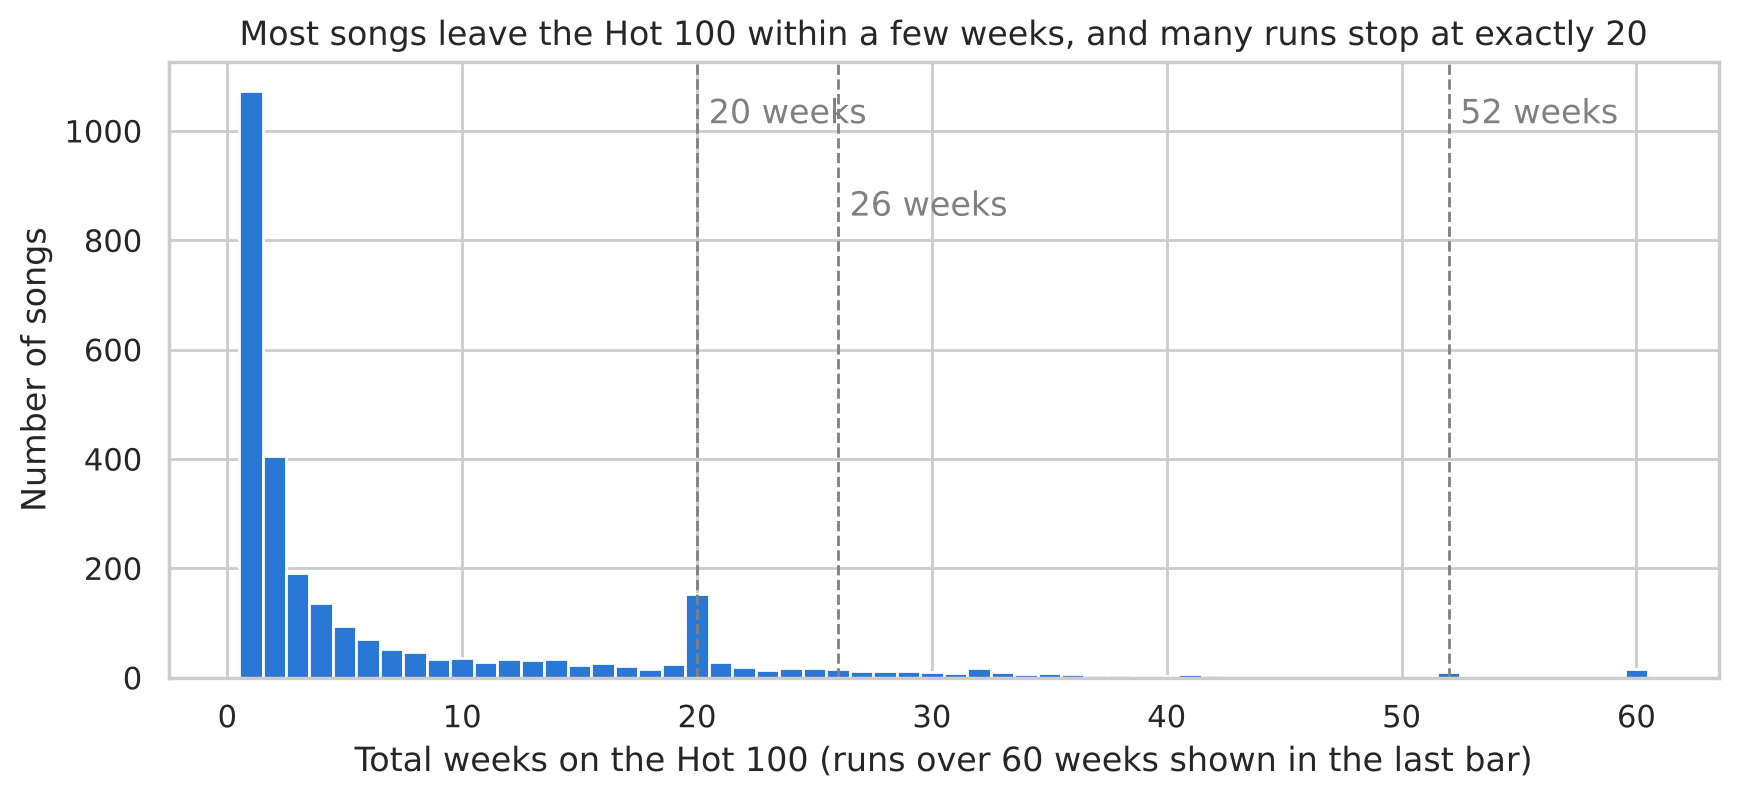

In [3]:
# Outcome: total weeks on the chart for finished runs
weeks = df.loc[df["complete_run"], "weeks_on_chart_total"]

print(weeks.describe().round(1).to_string())
print("skew:", round(weeks.skew(), 2))
print("1 week only:", round((weeks == 1).mean(), 3))
print("4 weeks or less:", round((weeks <= 4).mean(), 3))
print("20+ weeks:", round((weeks >= 20).mean(), 3))
print("runs ending at 19 / 20 / 21 weeks:", (weeks == 19).sum(), (weeks == 20).sum(), (weeks == 21).sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(weeks.clip(upper=60), bins=np.arange(0.5, 61.5, 1), color=BLUE, edgecolor="white")
for cutoff, height in [(20, 0.9), (26, 0.75), (52, 0.9)]:  # Billboard removal rules
    ax.axvline(cutoff, color="gray", linestyle="--", linewidth=1)
    ax.text(cutoff + 0.5, ax.get_ylim()[1] * height, f"{cutoff} weeks", color="gray")
ax.set_xlabel("Total weeks on the Hot 100 (runs over 60 weeks shown in the last bar)")
ax.set_ylabel("Number of songs")
ax.set_title("Most songs leave the Hot 100 within a few weeks, and many runs stop at exactly 20")
plt.show()

Most songs leave the Hot 100 fast, and a few stay for a very long time. The median finished run (the middle song) lasts **2 weeks**, while the average is 7.6 weeks and the longest run is 112 weeks. **38.0% of songs last a single week**, 64.0% last 4 weeks or less, and only 15.8% last 20 weeks or more. This lopsided shape is called right-skewed (skew 2.60, where 0 would mean balanced).

The histogram also spikes at exactly 20 weeks: 153 runs end there, compared with 25 at 19 weeks and 29 at 21 weeks. Billboard's 20-week rule causes this, since songs below No. 50 are removed as soon as they reach 20 weeks.

Because of this lopsided shape, a straight-line model of raw weeks would be pulled toward the few songs that last 50 to 112 weeks and would fit the typical 1 to 10 week song poorly. We handle this in two ways. The first is to model *log(weeks)*, which squeezes long runs together: on a log scale, going from 1 to 2 weeks counts the same as going from 10 to 20, so one 100-week song no longer dominates. The second is to sort songs into *quick spikes* (1 to 4 weeks), *middle runs* (5 to 19 weeks), and *long runs* (20+ weeks). The removal rule makes 20 weeks a natural cutoff for a long run.

**Phase 3 update:** we use both. Hypothesis 1 asks whether a song reaches 20 weeks (a yes/no outcome), and every model that predicts a number of weeks uses log(weeks).

**Figure 2. How do long runs and quick spikes differ in their first two weeks?**

We group songs by total run (1 week, 2 to 4, 5 to 19, and 20+ weeks) and compare two things we know early: debut rank and week-2 movement. We use box plots because each group holds hundreds of songs, and the spread matters as much as the middle. In a box plot, the box holds the middle half of the songs, the line inside it is the median, the whiskers show the usual range, and dots are unusual songs. One-week songs appear in the debut-rank panel; they have no week-2 rank, so the right panel starts at 2 to 4 weeks.

,songs,median_debut_rank,songs_on_chart_in_week_2,median_week2_change
run_length,,,,
1 week,852,74.0,0,NaN
2-4 weeks,587,44.0,538,-35.0
5-19 weeks,502,54.0,456,-7.0
20+ weeks,409,49.0,370,-0.5


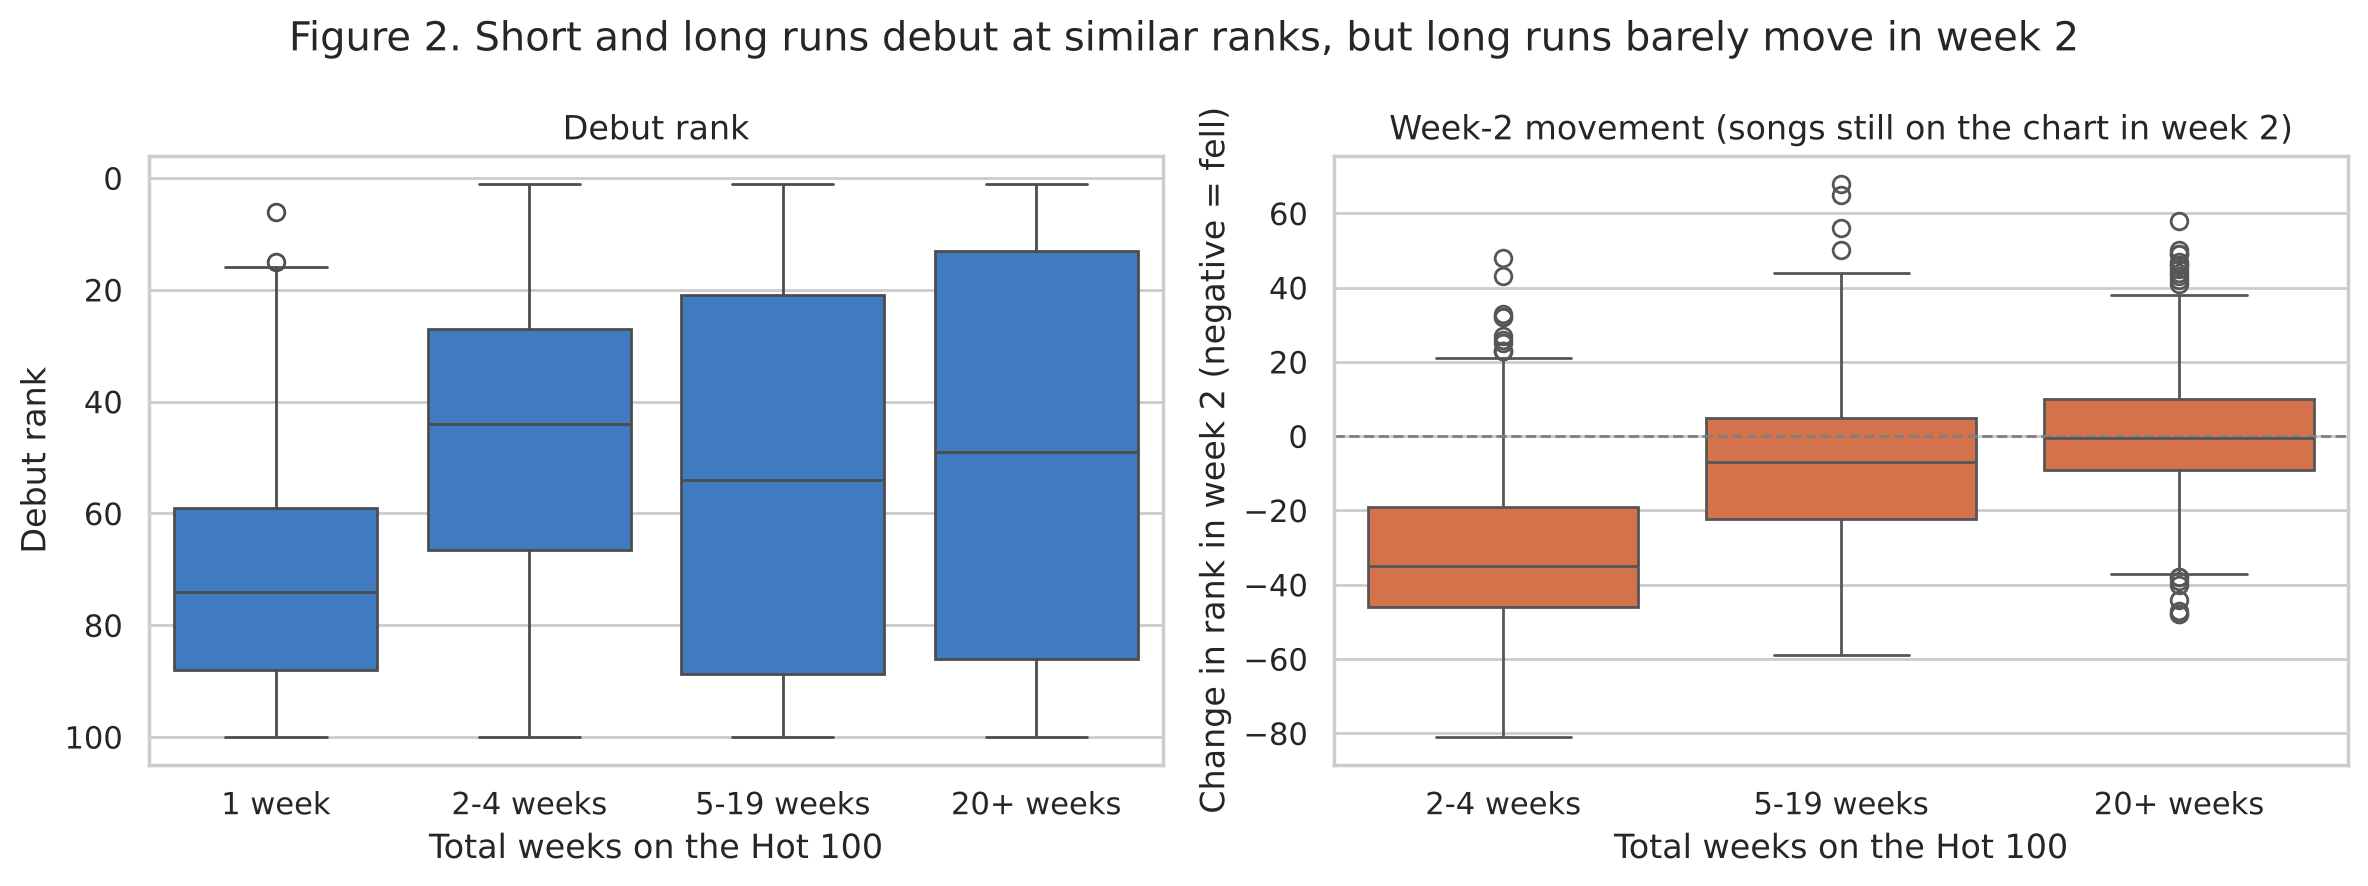

In [4]:
# Figure 2: debut rank and week-2 movement for each run length (songs followed at least a year)
fig2 = followed.copy()
order = ["1 week", "2-4 weeks", "5-19 weeks", "20+ weeks"]
fig2["run_length"] = pd.cut(fig2["weeks_on_chart_total"], bins=[0, 1, 4, 19, 1000], labels=order)
display(fig2.groupby("run_length", observed=True)
            .agg(songs=("debut_rank", "size"), median_debut_rank=("debut_rank", "median"),
                 songs_on_chart_in_week_2=("week2_change", "count"), median_week2_change=("week2_change", "median")))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=fig2, x="run_length", y="debut_rank", order=order, color=BLUE, ax=axes[0])
axes[0].invert_yaxis()  # No. 1 at the top
axes[0].set_xlabel("Total weeks on the Hot 100")
axes[0].set_ylabel("Debut rank")
axes[0].set_title("Debut rank")
sns.boxplot(data=fig2.dropna(subset=["week2_change"]), x="run_length", y="week2_change", order=order[1:],
            color=ORANGE, ax=axes[1])
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("Total weeks on the Hot 100")
axes[1].set_ylabel("Change in rank in week 2 (negative = fell)")
axes[1].set_title("Week-2 movement (songs still on the chart in week 2)")
fig.suptitle("Figure 2. Short and long runs debut at similar ranks, but long runs barely move in week 2")
plt.tight_layout()
plt.show()

One-week songs debut much lower (median No. 74), so a low debut is a warning sign. Among songs that last longer, debut rank barely separates them: quick spikes (2 to 4 weeks) debut at a median of No. 44 and long runs at No. 49. They split apart in week 2. Quick spikes fall a median of 35 spots, middle runs fall 7, and long runs barely move (a median drop of half a spot). That makes **the size of the week-2 drop** a promising early signal.

**Phase 3 change (TA feedback):** in Phase 2 this was a line chart of median rank by week that left out one-week songs. The line connected medians of a shrinking set of songs (quick spikes drop out after week 4), so we switched to box plots and added one-week songs as their own group.

## Preregistration statements
*These are our Phase 2 preregistration statements. Following TA feedback, we reworded each hypothesis as "X is associated with Y, holding Z constant"; the hypotheses and analyses are the same. Our Phase 3 additions follow them.*

We based these hypotheses on our EDA plots and rank (Spearman) correlations. We have not fit any of the models below or run any significance tests.

### Preregistration Statement 1

**Hypothesis 1:** Among songs still on the Hot 100 in their second week, the number of spots a song drops in week 2 is negatively associated with its chance of lasting 20 or more weeks, holding debut rank and album release constant.

A song's debut week includes the release-week burst from its most dedicated fans. If casual listeners don't keep playing it, the song falls sharply in week 2 and has little left to keep it on the chart. Our EDA fits this idea: short and long runs debut at the same median rank (No. 45), but in week 2 short runs fall to a median of No. 79 while long runs hold at No. 48. (These are our Phase 2 numbers. After our Phase 3 cleaning fixes, Figure 2 shows the same pattern: quick spikes and long runs debut at a median of No. 44 and No. 49, then fall a median of 35 spots and half a spot in week 2.)

**Analysis:** We use songs with `followed_1yr` = True and at least 2 weeks on the chart. We run a logistic regression where we input `week2_change` (positive = climbed), `debut_rank`, and `album_track`, and output `long_run` (1 = 20+ weeks). A bigger drop gives a more negative `week2_change`, so we will test whether β_week2_change > 0, meaning songs that climb are more likely to last. As a secondary check, we run a linear regression with the same inputs and log(weeks on the Hot 100) as the output.

### Preregistration Statement 2

**Hypothesis 2:** Being an established artist is negatively associated with a song's weeks on the Hot 100, holding debut rank and album release constant. Established artists have large fan bases that stream a new song right away, which can push it to a high debut that fades quickly. A newer artist who debuts at the same position likely got there through broader demand, which tends to last longer. In our EDA, album tracks explained about half of the gap between new and established artists, but a gap remained among non-album songs (28% of songs by new artists reached 20 weeks, compared with 20% for artists with 10+ earlier hits).

**Analysis:** We define `established` as a dummy (a yes/no variable coded 1 or 0) equal to 1 if the lead artist had a Hot 100 entry in the 3 years before the song's debut. To look back 3 years for songs that debuted in 2022 to 2024, we use the full archive (including pre-2022 charts) only for this flag. The exact ranks in older charts are less reliable, but we only need to know whether an artist charted at all, so small errors matter little. We use songs with `followed_1yr` = True and run a linear regression where we input `established`, `debut_rank`, and `album_track`, and output log(weeks on the Hot 100). Newer artists are the reference group (the group we compare against), so we will test whether β_established < 0, meaning established artists' songs last fewer weeks. We will also add an interaction between `established` and a top-20 debut dummy to check whether the effect is strongest for songs that debut in the top 20.

### Preregistration Statement 3

**Hypothesis 3:** The share of a song's first two weeks of Spotify streams that came in week 1 (F) is negatively associated with its weeks on the Hot 100, holding total early streams constant. A song streamed mostly in its first week was likely driven by fans checking out a new release, while a song whose streams hold up is spreading to casual listeners and playlists, which is what keeps a song on the chart for months. Our EDA found that songs with more first-week streams tended to have longer runs (a rank correlation of 0.49, where 0 means no relationship and 1 means the two rankings match exactly), but that number alone cannot tell a fan-driven spike apart from a song that keeps growing.

**Analysis:** We will download Spotify weekly charts from October 2024 to October 2025, so that every matched song's Billboard run has finished. For each song, we compute a front-loading ratio F = (streams in its first week on the Top 200) ÷ (streams in its first 2 weeks on the Top 200). F near 1 means a spike, F near 0.5 means steady streams, and F below 0.5 means growing streams. If the song falls out of the Top 200 in week 2, that week counts as 0 streams. We run a linear regression where we input F and log(total streams in the first 2 weeks), and output log(weeks on the Hot 100). We will test whether β_F < 0, meaning front-loaded songs last fewer weeks. As a robustness check, we replace a missing week 2 with that week's No. 200 stream count, which is the most the song could have had.

### Phase 3 additions

**Related work behind each hypothesis.**
- *Hypothesis 1.* Treating a chart run as a question of how long a song lasts before it leaves follows Bradlow and Fader (2001), who modeled the "lifetime" of Hot 100 songs. Pessa et al. (2026) find that songs usually chart in one unbroken run and that attention to songs fades faster than attention to albums, which fits the idea that the first weeks are informative.
- *Hypothesis 2.* Studies of cultural markets find that early popularity is driven partly by social influence and is hard to predict from song features alone (Salganik, Dodds and Watts, 2006; Askin and Mauskapf, 2017), which makes who the artist is a plausible signal.
- *Hypothesis 3.* Billboard's own rule change in October 2025 (Thompson, 2025) responded to songs lingering on the chart for months, which shows that how long listening holds up, not just how high it starts, shapes a chart run.

**Why each answer matters either way.**
- *Hypothesis 1.* If week-2 movement predicts long runs, labels and playlist curators get a usable signal one week after release, long before a song's fate is known. If it does not, a song's first weeks are mostly noise, and decisions made in week 2 are guesswork.
- *Hypothesis 2.* If established artists' songs fade faster from the same debut rank, a high debut from a big name is weaker evidence of a hit than the same debut from a newcomer, which matters for where promotion money goes. If not, a debut rank means the same thing whoever the artist is.
- *Hypothesis 3.* If front-loaded streaming predicts a short run, streaming data can explain *why* a song falls in week 2 and flag fan-driven spikes early. If it does not, the shape of early streaming adds nothing beyond the total number of streams.

**How we test significance.** Each test only counts evidence in the direction we predicted (a one-sided test). Because we test three hypotheses, we also hold each result to a stricter bar of 0.05 / 3 ≈ 0.017 (a Bonferroni correction), which keeps the overall chance of a false alarm across the three tests near 5%. Our linear regressions use robust (HC1) standard errors, which keep the margins of error honest when some songs' run lengths vary more than others'. Because songs by the same artist are not independent, we also rerun every main test with clustered standard errors (see Evaluation of significance).

**Change to Preregistration Statement 1.** "At least 2 weeks on the chart" now means the song is on the chart the week right after its debut. While checking our work, we found that our Phase 2 code took "week 2" from a song's second week on the chart, which for about 130 songs was a re-entry weeks or months later. The hypothesis and model are unchanged.

**Change to Preregistration Statement 2 (TA feedback).** Our TA felt the `established` flag is too generous. We keep it for the preregistered test and add two stricter definitions as a robustness check.

**Changes to Preregistration Statement 3.**
- **Which songs (TA feedback).** We asked whether counting a week outside the Top 200 as 0 streams was reasonable, and our TA said it is not valid and that we should keep only songs in the Top 200 for both weeks. Our main test now does that, and we keep the preregistered version as a secondary check so readers can compare.
- **Which weeks (TA feedback).** We planned to use Spotify charts from October 2024 to October 2025, so every song's run would be finished. Our TA suggested getting Spotify charts for the same years as our Billboard data, so we downloaded every week from January 2022 to October 2026. Our main test now uses every song followed for at least a year (debuts from January 2022 to October 2025), the same rule as Hypotheses 1 and 2, so the runs are finished and the sample is about four times larger. We also rerun the test on the October 2024 to October 2025 debuts alone, as preregistered.
- **An added check.** A Cox proportional-hazards model (Cox, 1972) on all debuts through 2026, which counts still-charting songs only for the weeks we have seen. This also responds to our first Phase 2 reviewer question.

## Data analysis

### How to read our statistics
We use a few standard tools. Here is what each one means in plain terms.
- **Regression.** A method that estimates how an outcome (here, how long a song lasts) changes with several inputs at once. "Holding X constant" means we compare songs that are alike on X, for example songs that debuted at the same rank.
- **Coefficient (β).** The number a regression gives each input: how much the outcome changes when that input goes up by one unit.
- **Logistic regression and odds ratios.** We use logistic regression when the outcome is yes/no (did the song last 20+ weeks?). Its results are odds ratios. Odds are the chance something happens divided by the chance it does not, so a 50% chance is odds of 1. An odds ratio above 1 makes a long run more likely, below 1 less likely, and 0.5 halves the odds.
- **Linear regression and log(weeks).** We use linear regression when the outcome is a number of weeks. Because we take the log of weeks, each result reads as a percent change in weeks on the chart; for example, −34% means about a third fewer weeks.
- **95% confidence interval (CI).** The range of values our data supports for an estimate. A narrow range means a precise estimate. When the range for an odds ratio leaves out 1 (or the range for a percent change leaves out 0%), the effect is unlikely to be a fluke.
- **p-value.** If there were truly no relationship, the p-value is the chance of seeing one at least as strong as ours by luck alone. We call a result statistically significant when p is below 0.05, and we also check our stricter bar of 0.017 (see Preregistration).
- **Null hypothesis.** The "no relationship" starting point. "Reject the null" means our data would be very unlikely if there were no relationship.
- **Control.** An input we add so a comparison is fair. For example, we control for album releases so album tracks are compared with album tracks.
- **Robustness check.** The same question asked a slightly different way, with a different sample or definition, to see whether the answer holds.
- **Correlation (r).** A number from −1 to 1 that measures how closely two things move together. 0 means no relationship, and −0.8 means that when one is high, the other is usually low.
- **Clustered standard errors.** Margins of error that treat all songs by the same lead artist as one group, since those songs tend to rise and fall together.
- **Unfinished runs (censoring).** Songs still on the chart when our data ends, whose final run length we do not know yet. Statisticians call these runs censored.
- **Cox model and hazard ratio (HR).** A model for "how long until something happens" that can use unfinished runs. It estimates each song's chance of leaving the chart in any given week (its hazard). A hazard ratio of 2 means a song is twice as likely to leave in a given week.
- **Kaplan–Meier curve.** A chart of the share of songs still on the Hot 100 after each week, which also handles unfinished runs.

### Hypothesis 1: week-2 movement
**Sample.** We use songs followed for at least a year that are still on the Hot 100 in the chart right after their debut (1,364 songs). That leaves out 986 songs (42.0%) with no week-2 rank: 852 charted for only one week, and 134 dropped off in week 2 and came back later. As our TA noted, this matches the hypothesis, which is about songs still on the chart in week 2. It does make long runs more common in our sample (27%) than among all debuts, since one-week songs can never reach 20 weeks. Of the 134 that came back, 39 later reached 20 weeks, a path our model cannot see.

**Model.** We use logistic regression, because the outcome is yes/no: did the song last 20 weeks or more? We report odds ratios (see the box above). The model includes debut rank and album release, so we compare songs that debuted at the same rank and were, or were not, part of an album release.

In [5]:
h1 = followed[followed["week2_change"].notna()].copy()
h1["long_run"] = h1["long_run"].astype(int)
h1["album_track"] = h1["album_track"].astype(int)
print("songs in H1 sample:", len(h1), "| share with a long run:", round(h1["long_run"].mean(), 3))
print(h1["week2_change"].describe().round(1).to_string())

logit1 = smf.logit("long_run ~ week2_change + debut_rank + album_track", data=h1).fit(disp=0)
print(logit1.summary2().tables[1].round(4))

odds = pd.DataFrame({"odds ratio": np.exp(logit1.params),
                     "95% CI low": np.exp(logit1.conf_int()[0]),
                     "95% CI high": np.exp(logit1.conf_int()[1])}).round(3)
odds

songs in H1 sample: 1364 | share with a long run: 0.271
count    1364.0
mean      -14.8
std        24.5
min       -81.0
25%       -34.0
50%       -12.0
75%         1.0
max        68.0
               Coef.  Std.Err.        z  P>|z|  [0.025  0.975]
Intercept     1.5285    0.1960   7.7968    0.0  1.1443  1.9127
week2_change  0.0623    0.0044  14.0880    0.0  0.0537  0.0710
debut_rank   -0.0327    0.0028 -11.4619    0.0 -0.0382 -0.0271
album_track  -1.0429    0.1769  -5.8959    0.0 -1.3896 -0.6962


,odds ratio,95% CI low,95% CI high
Intercept,4.611,3.140,6.772
week2_change,1.064,1.055,1.074
debut_rank,0.968,0.962,0.973
album_track,0.352,0.249,0.498


**Summarizing.** All three inputs point the way we expected:
- **Week-2 movement.** Each spot a song climbs in week 2 multiplies its odds of a long run by **1.064** (95% CI 1.055 to 1.074), about 6% better odds per spot. Each spot it falls multiplies the odds by about 0.94, about 6% worse.
- **Debut rank.** Each spot lower a song debuts (a larger rank number) multiplies the odds by 0.968, about 3% worse per spot.
- **Album tracks.** Album tracks have **0.35 times** the odds of a long run of other songs with the same debut rank and week-2 movement, a 65% cut in the odds.

The intercept is the model's starting value for a song that debuts at "No. 0" and does not move. It has no real meaning on its own.

One chart spot is a small unit. The typical song falls 12 spots in week 2, and the middle half of songs range from a 34-spot fall to a 1-spot climb. The next cell restates the effect for a 10-spot fall and shows the chance of a long run for a concrete song.

In [6]:
b, ci = logit1.params["week2_change"], logit1.conf_int().loc["week2_change"]
print(f"odds ratio for a 10-spot DROP in week 2: {np.exp(-10 * b):.2f} (95% CI {np.exp(-10 * ci[1]):.2f} to {np.exp(-10 * ci[0]):.2f})")

example = pd.DataFrame({"week2_change": [0, -10, -20, -40] * 2, "debut_rank": 40,
                        "album_track": [0] * 4 + [1] * 4})
example["P(long run)"] = logit1.predict(example).round(3)
display(example.rename(columns={"week2_change": "week-2 change (spots)"}))

# How much do week-2 changes add beyond debut rank and album status? Likelihood-ratio test.
logit0 = smf.logit("long_run ~ debut_rank + album_track", data=h1).fit(disp=0)
lr = 2 * (logit1.llf - logit0.llf)
print(f"pseudo R-squared without week2_change: {logit0.prsquared:.3f} | with it: {logit1.prsquared:.3f}")
print(f"likelihood-ratio statistic: {lr:.1f} on 1 df")

# Discrimination: AUC = chance a random long run gets a higher predicted probability than a random short one
p_hat = logit1.predict(h1)
y = h1["long_run"].values
ranks = rankdata(p_hat)
n1, n0 = y.sum(), len(y) - y.sum()
auc = (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
print(f"AUC: {auc:.3f} | accuracy at 0.5 cutoff: {((p_hat >= 0.5) == y).mean():.3f} "
      f"(always guessing 'short': {1 - y.mean():.3f})")

odds ratio for a 10-spot DROP in week 2: 0.54 (95% CI 0.49 to 0.58)


,week-2 change (spots),debut_rank,album_track,P(long run)
0,0,40,0,0.555
1,-10,40,0,0.401
2,-20,40,0,0.264
3,-40,40,0,0.094
4,0,40,1,0.306
5,-10,40,1,0.191
6,-20,40,1,0.112
7,-40,40,1,0.035


pseudo R-squared without week2_change: 0.063 | with it: 0.235
likelihood-ratio statistic: 275.1 on 1 df
AUC: 0.824 | accuracy at 0.5 cutoff: 0.788 (always guessing 'short': 0.729)


**Predicting.** Take a non-album song that debuts at No. 40:
- If it holds its rank in week 2, the model gives it a **56%** chance of a 20-week run.
- A 20-spot drop lowers that to **26%**.
- A 40-spot drop lowers it to **9%**.

The same moves for an album track give 31%, 11%, and 3.5%. In odds terms, a 10-spot fall multiplies the odds of a long run by 0.54, nearly halving them.

**How much does week 2 add?** A lot. Pseudo R² is a 0-to-1 score of how well a yes/no model explains the outcome. It rises from 0.063 with only debut rank and album release to 0.235 once we add week-2 movement, almost four times as much. A likelihood-ratio test asks whether that improvement could be luck: its value is 275.1, far above the 3.84 needed for p < 0.05.

**How good are its calls?** The model is good at sorting songs by risk. Its AUC is 0.82, which means that if we pick one long-run song and one short-run song at random, the model gives the long-run song the higher chance 82% of the time (a coin flip would get 50%). It is weaker at yes/no calls: predicting "long run" whenever the chance is above 50% is right 79% of the time, only a little better than always guessing "short" (73%), since most songs are short.

**Figure 3** shows the chance of a long run across the whole range of week-2 movement.

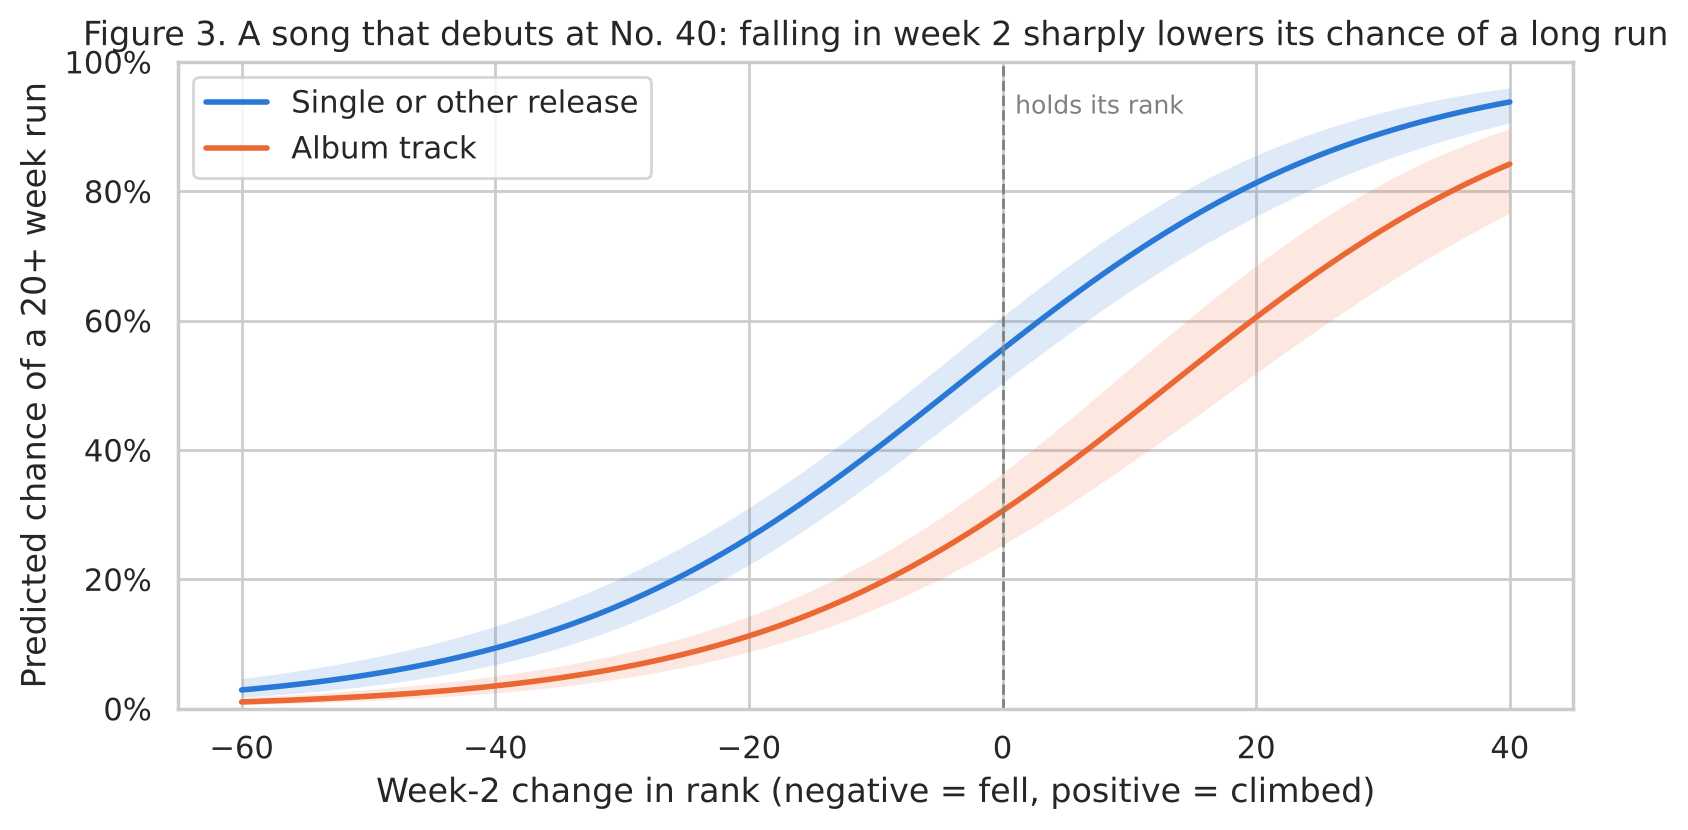

In [7]:
grid = pd.DataFrame({"week2_change": np.arange(-60, 41)})
fig, ax = plt.subplots(figsize=(9, 4.2))
for album, color, label in [(0, BLUE, "Single or other release"), (1, ORANGE, "Album track")]:
    g = grid.assign(debut_rank=40, album_track=album)
    pred = logit1.get_prediction(g).summary_frame()
    ax.plot(g["week2_change"], pred["predicted"], color=color, linewidth=2, label=label)
    ax.fill_between(g["week2_change"], pred["ci_lower"], pred["ci_upper"], color=color, alpha=0.15, linewidth=0)
ax.axvline(0, color="gray", linewidth=1, linestyle="--")
ax.text(1, 0.92, "holds its rank", color="gray", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_xlabel("Week-2 change in rank (negative = fell, positive = climbed)")
ax.set_ylabel("Predicted chance of a 20+ week run")
ax.set_title("Figure 3. A song that debuts at No. 40: falling in week 2 sharply lowers its chance of a long run")
ax.legend(loc="upper left")
plt.show()

The shaded bands show the 95% confidence interval, the range of chances our data supports. Album tracks sit well below other releases at every level of week-2 movement. Both curves rise steeply between a 40-spot drop and holding steady, which is the range where most songs fall.

**Secondary check: number of weeks.** Our preregistered linear regression asks the same question using each song's full run length (as log(weeks)), not only whether it reached 20 weeks. We use robust (HC1) standard errors, which keep the margins of error honest when some songs' run lengths vary more than others'.

In [8]:
ols1 = smf.ols("log_weeks ~ week2_change + debut_rank + album_track", data=h1).fit(cov_type="HC1")
print(ols1.summary2().tables[1].round(4))
print(f"R-squared: {ols1.rsquared:.3f}")
print(f"each spot gained in week 2 -> {np.exp(ols1.params['week2_change']) - 1:+.1%} weeks on the chart")
print(f"each 10 spots lost in week 2 -> {np.exp(-10 * ols1.params['week2_change']) - 1:+.1%} weeks on the chart")
print(f"album track -> {np.exp(ols1.params['album_track']) - 1:+.1%} weeks on the chart")
resid = ols1.resid
print(f"residuals: mean {resid.mean():.3f}, sd {resid.std():.2f}, skew {resid.skew():.2f}")

               Coef.  Std.Err.        z  P>|z|  [0.025  0.975]
Intercept     3.4926    0.0508  68.7755    0.0  3.3931  3.5922
week2_change  0.0286    0.0010  29.0153    0.0  0.0267  0.0306
debut_rank   -0.0169    0.0008 -21.7710    0.0 -0.0184 -0.0154
album_track  -0.5742    0.0478 -12.0072    0.0 -0.6679 -0.4805
R-squared: 0.478
each spot gained in week 2 -> +2.9% weeks on the chart
each 10 spots lost in week 2 -> -24.9% weeks on the chart
album track -> -43.7% weeks on the chart
residuals: mean 0.000, sd 0.74, skew 0.33


The linear model agrees with the logistic one:
- **Week-2 movement.** Each 10 spots lost in week 2 goes with about **25% fewer** weeks on the chart.
- **Album tracks.** They chart about 44% fewer weeks.
- **Fit.** The three early signals explain 48% of the differences in log(weeks) between songs (R² = 0.48, where 1 would mean they explain everything).
- **Model misses (residuals).** The gaps between predicted and actual log(weeks) are roughly balanced (skew 0.33), with no long one-sided tail, which tells us taking the log worked.

**Outliers and oddities.** The next cell lists the songs the logistic model got most wrong.

In [9]:
h1["p_long"] = p_hat
cols = ["title", "artist", "debut_rank", "week2_change", "album_track", "weeks_on_chart_total", "p_long"]
print("Long runs the model gave under a 5% chance:")
display(h1[(h1["long_run"] == 1) & (h1["p_long"] < 0.05)][cols].sort_values("p_long").round(3))
print("Short runs the model gave over a 90% chance:")
display(h1[(h1["long_run"] == 0) & (h1["p_long"] > 0.9)][cols].round(3))

Long runs the model gave under a 5% chance:


,title,artist,debut_rank,week2_change,album_track,weeks_on_chart_total,p_long
108,All Mine,Brent Faiyaz,42,-47.0,1,20,0.022
1979,One Thing At A Time,Morgan Wallen,37,-44.0,1,30,0.030


Short runs the model gave over a 90% chance:


,title,artist,debut_rank,week2_change,album_track,weeks_on_chart_total,p_long
919,Fingers Crossed,Lauren Spencer-Smith,69,50.0,0,19,0.916
1176,Heyy,Lil Baby,77,56.0,0,12,0.924
2029,Painting Pictures,Superstar Pride,99,65.0,0,15,0.913
2576,Surface Pressure,Jessica Darrow,54,40.0,0,19,0.905
2758,Tobey,"Eminem, Big Sean & BabyTron",95,68.0,0,5,0.935


The surprises are few, and they show what the model cannot see:
- **Morgan Wallen's "One Thing At A Time."** It debuted at No. 37 in December 2022 with the two other songs on his 3-song sampler EP, so our flag counts it as an album track. It fell 44 spots in week 2, yet lasted 30 weeks after it was promoted to country radio, where it reached No. 1 on MusicRow's radio chart in May 2023 (Cantrell, 2023).
- **Brent Faiyaz's "All Mine."** It also crashed in week 2 (47 spots), then grew slowly into a 20-week run.
- **Big week-2 climbs that still fell short.** Five songs that jumped 40 to 68 spots in week 2 did not reach 20 weeks. Two of them, Lauren Spencer-Smith's "Fingers Crossed" and "Surface Pressure" from *Encanto*, lasted 19 weeks, one short of our cutoff. Eminem, Big Sean and BabyTron's "Tobey" debuted at No. 95, jumped 68 spots, and still left after 5 weeks.

**Lesson.** Promotion after week 2, such as radio, can override the early signal. A yes/no cutoff also treats a 19-week run like a 1-week run, which is why we also check log(weeks).

**A built-in constraint.** A song that debuts at No. 1 cannot climb, while a song at No. 95 can climb 94 spots. So `week2_change` and `debut_rank` are not independent. This is why we kept debut rank in every model.

**Keeping more songs (TA feedback).** Our TA asked whether we need to drop the songs that debuted in the last year. Our yes/no outcome is already known for any song that has reached 20 weeks or has left the chart, so we rerun the logistic model on all of those debuts.

In [10]:
# Robustness (TA feedback): keep every debut whose 20-week outcome is already known, not only songs followed a year.
# The outcome is known once a song has reached 20 weeks or has left the chart.
known = df[df["new_entry"] & df["week2_change"].notna()
           & ((df["weeks_on_chart_total"] >= 20) | ~df["still_charting"])].copy()
known["long_run"] = known["long_run"].astype(int)
known["album_track"] = known["album_track"].astype(int)
logit1_all = smf.logit("long_run ~ week2_change + debut_rank + album_track", data=known).fit(disp=0)
b_all = logit1_all.params["week2_change"]
print(f"songs: {len(known)} (main sample: {len(h1)})")
print(f"odds ratio for a 10-spot drop in week 2: {np.exp(-10 * b_all):.2f}, two-sided p = {logit1_all.pvalues['week2_change']:.1g}")

songs: 1619 (main sample: 1364)
odds ratio for a 10-spot drop in week 2: 0.53, two-sided p = 1e-51


With 1,619 songs, a 10-spot drop multiplies the odds of a long run by 0.53, almost the same as 0.54 in the main sample. We keep the 1-year sample as our main test because it was preregistered and because the log(weeks) model needs final run lengths.

### Hypothesis 2: established artists
**Sample and outcome.** We use all 2,350 songs followed for at least a year, including one-week runs, since this test does not need a week-2 rank. The outcome is log(weeks).

**Reading the results.** Because the outcome is log(weeks), each result reads as a percent change in weeks on the chart (we convert a coefficient β with e^β − 1).

**Who counts as established.** 84% of debuts are by established artists, so "newer artist" is the minority group.

In [11]:
h2 = followed.copy()
h2["established"] = h2["established"].astype(int)
h2["album_track"] = h2["album_track"].astype(int)
h2["top20"] = (h2["debut_rank"] <= 20).astype(int)
print("songs:", len(h2), "| share by established artists:", round(h2["established"].mean(), 3))
display(h2.groupby(["top20", "established"])["weeks_on_chart_total"]
          .agg(songs="size", median_weeks="median", mean_weeks="mean").round(1))

ols2 = smf.ols("log_weeks ~ established + debut_rank + album_track", data=h2).fit(cov_type="HC1")
print(ols2.summary2().tables[1].round(4))
print(f"R-squared: {ols2.rsquared:.3f}")
eff, ci = ols2.params["established"], ols2.conf_int().loc["established"]
print(f"established artist -> {np.exp(eff) - 1:+.1%} weeks (95% CI {np.exp(ci[0]) - 1:+.1%} to {np.exp(ci[1]) - 1:+.1%})")

songs: 2350 | share by established artists: 0.842


songs  median_weeks  mean_weeks
top20 established                                 
0     0              354           6.0        12.2
      1             1649           2.0         5.8
1     0               17          20.0        18.0
      1              330          12.0        16.2

              Coef.  Std.Err.        z  P>|z|  [0.025  0.975]
Intercept    3.3862    0.0850  39.8446    0.0  3.2197  3.5528
established -0.4186    0.0747  -5.6024    0.0 -0.5650 -0.2721
debut_rank  -0.0195    0.0007 -26.5848    0.0 -0.0209 -0.0181
album_track -1.2071    0.0436 -27.6836    0.0 -1.2926 -1.1217
R-squared: 0.307
established artist -> -34.2% weeks (95% CI -43.2% to -23.8%)


**The raw numbers.** Before any model, newer artists' songs last longer both outside the top 20 (median 6 weeks against 2) and inside it (20 against 12). Inside the top 20, most of that gap is album releases: 70% of established artists' top-20 debuts are album tracks, against 4 of 17 for newer artists, and among non-album top-20 debuts both groups have a median of 20 weeks.

**Summarizing.** At the same debut rank and album status, songs by established artists spend about **34% fewer weeks** on the chart (95% CI 24% to 43% fewer). That supports the hypothesis on average.

Album tracks are still the largest single factor: about 70% fewer weeks (e^−1.207 − 1). Each spot lower at debut costs about 2% of run length.

**The top-20 check (an interaction).** We preregistered a check of whether the established-artist effect is strongest among top-20 debuts. An interaction lets an effect differ between two groups. In this model, the `established` result is the effect for songs that debut **outside** the top 20, and adding `established:top20` to it gives the effect **inside** the top 20.

In [12]:
ols2b = smf.ols("log_weeks ~ established * top20 + debut_rank + album_track", data=h2).fit(cov_type="HC1")
print(ols2b.summary2().tables[1].round(4))
print(f"R-squared: {ols2b.rsquared:.3f}")
outside = ols2b.params["established"]
inside_test = ols2b.t_test("established + established:top20 = 0")
inside = float(np.squeeze(inside_test.effect))
print(f"established effect OUTSIDE the top 20: {np.exp(outside) - 1:+.1%} weeks")
print(f"established effect INSIDE the top 20:  {np.exp(inside) - 1:+.1%} weeks "
      f"(two-sided p = {float(np.squeeze(inside_test.pvalue)):.3f})")

                    Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
Intercept          2.8930    0.1002  28.8579  0.0000  2.6965  3.0894
established       -0.4716    0.0755  -6.2425  0.0000 -0.6196 -0.3235
top20             -0.0176    0.2981  -0.0590  0.9530 -0.6019  0.5667
established:top20  0.8644    0.2968   2.9122  0.0036  0.2827  1.4461
debut_rank        -0.0128    0.0010 -12.8629  0.0000 -0.0148 -0.0109
album_track       -1.1465    0.0438 -26.1563  0.0000 -1.2324 -1.0606
R-squared: 0.337
established effect OUTSIDE the top 20: -37.6% weeks
established effect INSIDE the top 20:  +48.1% weeks (two-sided p = 0.174)


**The interaction runs the opposite way from our prediction:**
- **Outside the top 20**, established artists chart about **38% fewer weeks** than newer artists.
- **Inside the top 20**, the sign flips. Established artists' songs chart about 48% *longer*, but with only 17 newer-artist top-20 debuts this is not significant (p = 0.17).
- **The interaction itself is significant** (p = 0.004). The established-artist penalty is a feature of mid- and low-chart debuts, not of big debuts.

**Figure 4** shows the model's predicted weeks for a non-album song at each debut rank.

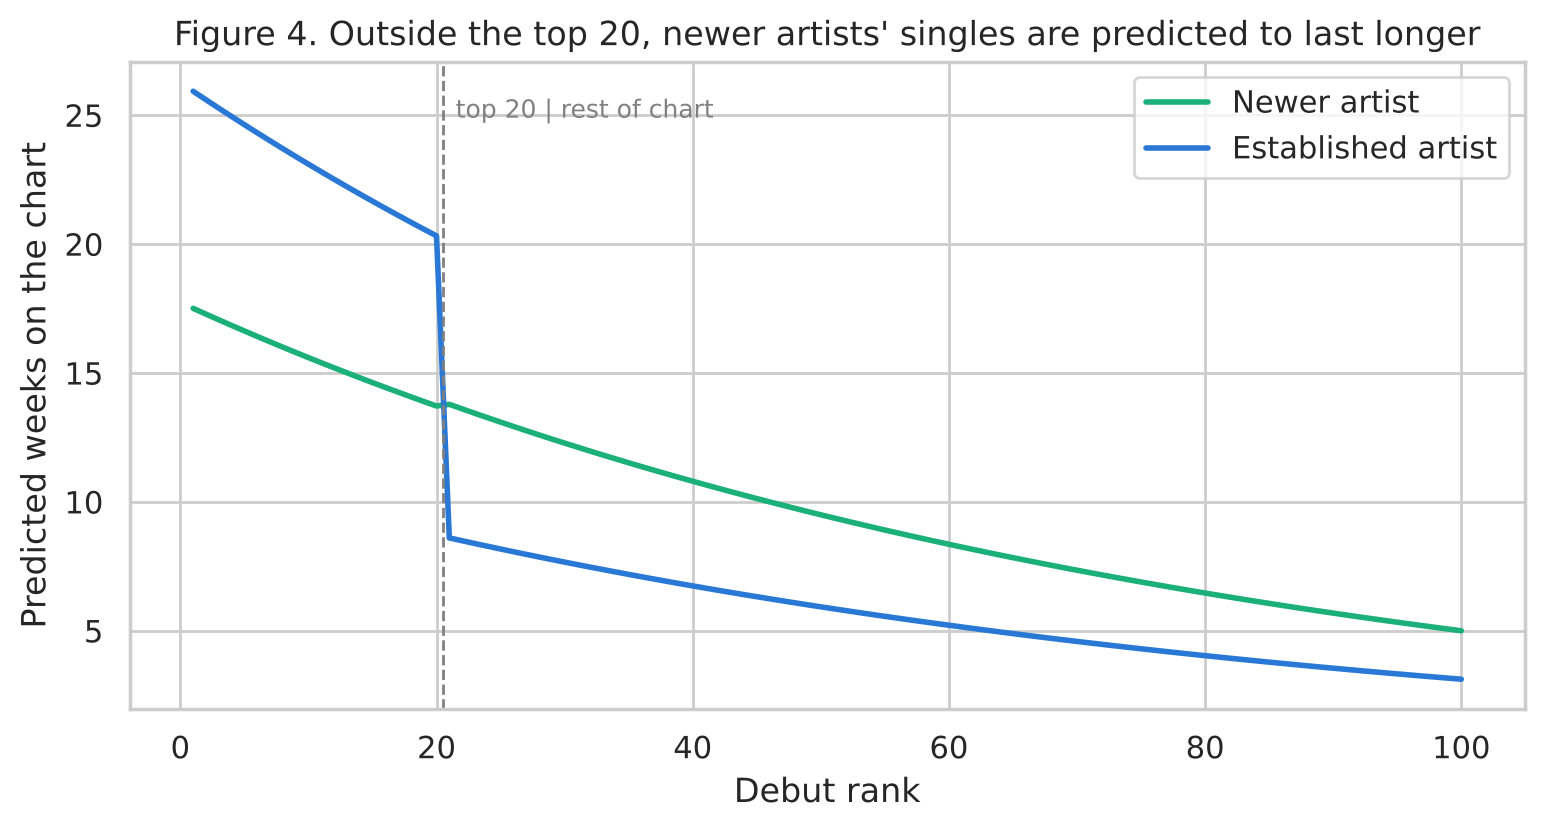

Newer-artist top-20 debuts (all 17):


,title,artist,debut_rank,album_track,weeks_on_chart_total
2678,The Heart Part 5,Kendrick Lamar,15,0,2
1934,Now And Then,The Beatles,7,0,2
539,CN Tower,PARTYNEXTDOOR & Drake,18,1,3
116,All Red,Playboi Carti,15,0,4
230,Bad Decisions,"benny blanco, BTS & Snoop Dogg",10,0,5
2477,Soy El Unico,Yahritza y Su Esencia,20,0,5
2345,Selfish,Justin Timberlake,19,0,13
466,Carnival,¥$: Kanye West & Ty Dolla $ign,3,1,19
1690,MAMIII,Becky G X Karol G,15,0,20
2236,Rich Men North Of Richmond,Oliver Anthony Music,1,0,20


In [13]:
grid = pd.DataFrame({"debut_rank": np.arange(1, 101)})
grid["top20"] = (grid["debut_rank"] <= 20).astype(int)
fig, ax = plt.subplots(figsize=(9, 4.2))
for est, color, label in [(0, GREEN, "Newer artist"), (1, BLUE, "Established artist")]:
    g = grid.assign(established=est, album_track=0)
    ax.plot(g["debut_rank"], np.exp(ols2b.predict(g)), color=color, linewidth=2, label=label)
ax.axvline(20.5, color="gray", linestyle="--", linewidth=1)
ax.text(21.5, ax.get_ylim()[1] * 0.92, "top 20 | rest of chart", color="gray", fontsize=9)
ax.set_xlabel("Debut rank")
ax.set_ylabel("Predicted weeks on the chart")
ax.set_title("Figure 4. Outside the top 20, newer artists' singles are predicted to last longer")
ax.legend()
plt.show()

print("Newer-artist top-20 debuts (all 17):")
display(h2[(h2["top20"] == 1) & (h2["established"] == 0)]
          [["title", "artist", "debut_rank", "album_track", "weeks_on_chart_total"]]
          .sort_values("weeks_on_chart_total"))

**Predicting.** For a non-album single that debuts at No. 50, the model predicts about 9.5 weeks for a newer artist and 6 for an established one (Figure 4). Because the model works on log(weeks), these predictions describe a typical song, close to the median, not the average.

**Outliers and oddities.** The 17 newer-artist top-20 debuts are a mixed group:
- **Breakout hits.** Some were genuine breakouts that lasted 20+ weeks, such as Tommy Richman's "Million Dollar Baby" (33 weeks) and Oliver Anthony's "Rich Men North Of Richmond" (20).
- **Flagged "new" by a technicality.** Others are famous artists our flag calls new: The Beatles' "Now And Then" (no Hot 100 hit as lead artist in the past 3 years), Kendrick Lamar's "The Heart Part 5," and Kanye West's "Carnival," which was credited to his group ¥$.

**Takeaway.** With so few songs and a flag that misses features and side projects, the top-20 result is suggestive, not reliable.

**Robustness.** The main effect holds in two smaller groups of songs:
- **Non-album songs only:** about −35% (see the next cell).
- **Songs that debuted from 2023 on:** about −33%. This guards against early-2022 debuts having a shorter look-back.

In [14]:
nonalbum = smf.ols("log_weeks ~ established + debut_rank", data=h2[h2["album_track"] == 0]).fit(cov_type="HC1")
late = smf.ols("log_weeks ~ established + debut_rank + album_track",
               data=h2[h2["first_week"] >= "2023-01-01"]).fit(cov_type="HC1")
print(f"non-album songs only (n={int(nonalbum.nobs)}): established -> {np.exp(nonalbum.params['established']) - 1:+.1%}, "
      f"p = {nonalbum.pvalues['established']:.2g}")
print(f"debuts from 2023 on (n={int(late.nobs)}): established -> {np.exp(late.params['established']) - 1:+.1%}, "
      f"p = {late.pvalues['established']:.2g}")

non-album songs only (n=1157): established -> -34.7%, p = 8e-07
debuts from 2023 on (n=1721): established -> -32.8%, p = 5.8e-06


**Stricter definitions (TA feedback).** Our TA felt the preregistered flag is too generous, since a single week anywhere on the Hot 100 in 3 years makes an artist established. We test two stricter versions, both as lead artist in the 3 years before the debut: 3 or more different Hot 100 songs, and at least one top-10 hit. We also rerun the test with a Cox model on all 2,924 debuts, which keeps songs from the last year as unfinished runs.

In [15]:
# Robustness (TA feedback): stricter definitions of "established"
rows = []
for flag, label in [("established", "Preregistered: any Hot 100 entry"),
                    ("established_3songs", "3 or more different Hot 100 songs"),
                    ("established_top10", "At least one top-10 hit")]:
    fit = smf.ols(f"log_weeks ~ {flag} + debut_rank + album_track", data=h2).fit(cov_type="HC1")
    rows.append({"established means (lead artist, past 3 years)": label,
                 "share of songs": round(h2[flag].mean(), 2),
                 "newer-artist top-20 debuts": int(((h2[flag] == 0) & (h2["top20"] == 1)).sum()),
                 "change in weeks": f"{np.exp(fit.params[flag]) - 1:+.0%}",
                 "two-sided p": round(fit.pvalues[flag], 4)})
display(pd.DataFrame(rows))

# Robustness (TA feedback): keep all debuts, using a Cox model that treats still-charting songs as unfinished
debuts = df[df["new_entry"]].copy()
cox_h2 = PHReg(debuts["weeks_on_chart_total"], debuts[["established", "debut_rank", "album_track"]].astype(float),
               status=debuts["complete_run"].astype(int)).fit()
print(f"all {len(debuts)} debuts: weekly hazard of leaving for established artists = "
      f"{np.exp(cox_h2.params[0]):.2f}x, two-sided p = {cox_h2.pvalues[0]:.1g}")

,"established means (lead artist, past 3 years)",share of songs,newer-artist top-20 debuts,change in weeks,two-sided p
0,Preregistered: any Hot 100 entry,0.84,17,-34%,0.0000
1,3 or more different Hot 100 songs,0.67,52,-20%,0.0001
2,At least one top-10 hit,0.49,76,-15%,0.0006


all 2924 debuts: weekly hazard of leaving for established artists = 1.36x, two-sided p = 2e-08


The direction holds, but the size depends on the definition. With the stricter flags, established artists chart 20% and 15% fewer weeks, against 34% with the preregistered flag, and all three are significant. A stricter flag moves artists with only one or two small hits into the "newer" group, and their songs behave more like established artists' songs, so the gap narrows. The Cox model on all debuts agrees: established artists' songs are 1.36 times as likely to leave the chart in any given week (p < 0.001). We report the preregistered estimate as the test and the stricter ones as the range.

### Hypothesis 3: front-loaded streaming
**Sample.** We start from Hot 100 debuts that matched a Spotify track and whose first two weeks on the Spotify Top 200 are both in our files (we also check the week before, so we know the first week is really the first). Then we apply three filters:
- **The 9-day check.** We keep only songs whose Billboard debut is exactly 9 days after their first Spotify week (`spotify_lag_days` = 9). This matches Billboard's chart dating, so a song's first Spotify week is the same week as its Billboard debut, and it screens out likely wrong matches.
- **Finished runs (TA feedback).** As in Hypotheses 1 and 2, we keep songs that debuted at least 52 weeks before our latest chart (January 2022 to October 2025), so we see almost every run to its end. Our full Spotify data is what makes this possible.
- **Both weeks in the Top 200 (TA feedback).** Our main test keeps only songs still in the Top 200 in their second week, so both weeks are real stream counts. The preregistered version, which counts a week outside the Top 200 as 0 streams, stays as a robustness check.

In [16]:
h3 = df[df["new_entry"] & df["spotify_first_in_window"].eq(True) & df["front_load"].notna()].copy()
print("matched debuts with an observable Spotify week 2:", len(h3))
h3 = h3[h3["spotify_lag_days"] == 9].copy()  # the gap is computed in the cleaning notebook
h3["log_streams_2wk"] = np.log(h3["streams_2wk"])
h3["album_track"] = h3["album_track"].astype(int)
h3["finished"] = h3["complete_run"].astype(int)
print("after the 9-day check:", len(h3))

# Every debut through 2026 that passes the checks, including songs still on the chart (used by the Cox check)
h3_all = h3[h3["fell_out_week2"].eq(False)].copy()

# Songs followed at least a year, as in Hypotheses 1 and 2
h3 = h3[h3["followed_1yr"]].copy()
print("followed at least a year:", len(h3))

# Preregistered version, kept as a robustness check: a week outside the Top 200 counts as 0 streams
h3_prereg = h3.copy()
h3_prereg["log_streams_2wk_upper"] = np.log(h3_prereg["streams_first_week"] + h3_prereg["streams_week2_upper"])

# Main sample (TA feedback): only songs in the Top 200 both weeks, so both weeks are real stream counts
h3 = h3[h3["fell_out_week2"].eq(False)].copy()
print("in the Top 200 both weeks:", len(h3), "| still charting:", int((1 - h3["finished"]).sum()),
      "| share with a long run:", round(h3["long_run"].mean(), 3))
print("debut years:", h3["first_week"].dt.year.value_counts().sort_index().to_dict())
print(h3["front_load"].describe().round(3).to_string())

# Run length for songs grouped by F
bands = pd.cut(h3["front_load"], [0, 0.5, 0.6, 0.7, 1], labels=["0.5 or less", "0.5 to 0.6", "0.6 to 0.7", "over 0.7"])
display(h3.groupby(bands, observed=True)
          .agg(songs=("front_load", "size"), median_weeks=("weeks_on_chart_total", "median"),
               share_long_run=("long_run", "mean"), share_album_tracks=("album_track", "mean"))
          .round(2).rename_axis("F (share of early streams in week 1)"))

matched debuts with an observable Spotify week 2: 2182
after the 9-day check: 1888
followed at least a year: 1566
in the Top 200 both weeks: 1067 | still charting: 1 | share with a long run: 0.23
debut years: {2022: 290, 2023: 285, 2024: 270, 2025: 222}
count    1067.000
mean        0.593
std         0.100
min         0.224
25%         0.530
50%         0.609
75%         0.662
max         0.827


,songs,median_weeks,share_long_run,share_album_tracks
F (share of early streams in week 1),,,,
0.5 or less,198,20.0,0.53,0.23
0.5 to 0.6,294,11.0,0.33,0.37
0.6 to 0.7,446,3.0,0.09,0.82
over 0.7,129,2.0,0.02,0.98


**What F looks like.** With both weeks in the Top 200, F ranges from 0.22 to 0.83 (median 0.61), so most songs get more streams in week 1 than in week 2. 198 songs had steady or growing streams (F of 0.5 or less).

**The raw pattern.** Before any model, run length falls steadily as F rises. Songs with F of 0.5 or less have a median run of 20 weeks, and 53% reach 20 weeks. Songs with F above 0.7 have a median run of 2 weeks, and only 2% reach 20 weeks. The table also shows a warning sign: album tracks make up 23% of the steadiest group and 98% of the most front-loaded one. We come back to this below.

**The preregistered regression** predicts log(weeks) from F, holding total early streams constant.

In [17]:
ols3 = smf.ols("log_weeks ~ front_load + log_streams_2wk", data=h3).fit(cov_type="HC1")
print(ols3.summary2().tables[1].round(4))
print(f"R-squared: {ols3.rsquared:.3f}")
b, ci = ols3.params["front_load"], ols3.conf_int().loc["front_load"]
print(f"F up by 0.1 -> {np.exp(0.1 * b) - 1:+.1%} weeks on the chart "
      f"(95% CI {np.exp(0.1 * ci[0]) - 1:+.1%} to {np.exp(0.1 * ci[1]) - 1:+.1%})")
print(f"residuals: skew {ols3.resid.skew():.2f}")

# Preregistered versions, kept as robustness checks
ols3p = smf.ols("log_weeks ~ front_load + log_streams_2wk", data=h3_prereg).fit(cov_type="HC1")
ols3u = smf.ols("log_weeks ~ front_load_upper + log_streams_2wk_upper", data=h3_prereg).fit(cov_type="HC1")
print(f"preregistered version, n = {len(h3_prereg)} (week outside the Top 200 = 0 streams): "
      f"beta_F = {ols3p.params['front_load']:.2f}, p = {ols3p.pvalues['front_load']:.2g}")
print(f"preregistered robustness (week outside the Top 200 = No. 200 streams): "
      f"beta_F = {ols3u.params['front_load_upper']:.2f}, p = {ols3u.pvalues['front_load_upper']:.2g}")

# The preregistered weeks only: debuts from Oct 12, 2024 (Spotify week of Oct 3, 2024) to Oct 18, 2025
window = h3[h3["first_week"] >= "2024-10-12"]
ols3w = smf.ols("log_weeks ~ front_load + log_streams_2wk", data=window).fit(cov_type="HC1")
print(f"preregistered weeks only (Oct 2024 to Oct 2025 debuts), n = {len(window)}: "
      f"F up by 0.1 -> {np.exp(0.1 * ols3w.params['front_load']) - 1:+.1%} weeks, p = {ols3w.pvalues['front_load']:.2g}")

                   Coef.  Std.Err.        z  P>|z|   [0.025  0.975]
Intercept       -10.0391    0.8082 -12.4218    0.0 -11.6231 -8.4551
front_load       -6.7475    0.2877 -23.4561    0.0  -7.3113 -6.1837
log_streams_2wk   0.9740    0.0497  19.6051    0.0   0.8767  1.0714
R-squared: 0.458
F up by 0.1 -> -49.1% weeks on the chart (95% CI -51.9% to -46.1%)
residuals: skew 0.38
preregistered version, n = 1566 (week outside the Top 200 = 0 streams): beta_F = -3.02, p = 2.9e-88
preregistered robustness (week outside the Top 200 = No. 200 streams): beta_F = -6.64, p = 1.9e-139
preregistered weeks only (Oct 2024 to Oct 2025 debuts), n = 269: F up by 0.1 -> -43.2% weeks, p = 2.3e-23


**Summarizing.** At the same total early streams, a song whose F is 0.1 higher, meaning 10 more percentage points of its early streams came in week 1, charts about **49% fewer weeks** (95% CI 46% to 52% fewer). Songs with more total early streams last longer. Together, F and total early streams explain 46% of the differences in log(weeks) (R² = 0.46), and the model's misses are roughly balanced (skew 0.38).

The preregistered versions agree:
- **0 streams for songs that fell out** (1,566 songs): β = −3.02, also significant. The effect is smaller because a song that falls out of the Top 200 gets F = 1, even if it only slipped just below No. 200.
- **No. 200 streams for songs that fell out:** β = −6.64, close to our main estimate.
- **Only the October 2024 to October 2025 debuts we preregistered** (269 songs): 43% fewer weeks per 0.1 of F.

In [18]:
# Predicting: weeks on the chart for songs with the median early streams and different F
typical = h3["log_streams_2wk"].median()
pred = pd.DataFrame({"front_load": [0.5, 0.6, 0.7], "log_streams_2wk": typical})
pred["predicted weeks"] = np.exp(ols3.predict(pred)).round(1)
display(pred.assign(**{"2-week streams (millions)": round(np.exp(typical) / 1e6, 1)}).drop(columns="log_streams_2wk"))

,front_load,predicted weeks,2-week streams (millions)
0,0.5,9.5,9.7
1,0.6,4.9,9.7
2,0.7,2.5,9.7


**Predicting.** Take three songs with the median 9.7 million streams across their first two weeks. The model predicts about 9.5 weeks on the chart for a steady song (F = 0.5), 4.9 weeks for a song with 60% of its early streams in week 1, and 2.5 weeks for a song with 70% in week 1. Because the model works on log(weeks), these describe a typical song, close to the median.

**Is F just a sign of an album release, or of the week-2 drop?** A confound is a third factor linked to both things we compare. Two are likely here:
- **Album releases.** Album tracks are much more front-loaded (median F 0.65, against 0.54 for other songs) and also have shorter runs (Hypothesis 1), so album releases could make F look important when it is not. We did not preregister an album control, but we add one, and we also rerun the test on non-album songs alone.
- **The week-2 drop.** Spotify streams count toward the Hot 100, so a song whose streams fade should also fall on Billboard in week 2, our Hypothesis 1 signal. If F only repeats the week-2 drop, it adds nothing new. We test this by adding week-2 movement and debut rank to the model.

**Unfinished runs.** Only 1 of these 1,067 songs is still charting. As a check that keeps recent songs too, we fit a Cox model (see the box at the start of Data analysis) on all 1,254 debuts from 2022 to 2026 that pass our checks, which counts still-charting songs only for the weeks we have seen. A hazard ratio (HR) above 1 means a song tends to leave sooner.

In [19]:
# Does F still matter after accounting for album releases and the week-2 drop?
ols3a = smf.ols("log_weeks ~ front_load + log_streams_2wk + album_track", data=h3).fit(cov_type="HC1")
ols3n = smf.ols("log_weeks ~ front_load + log_streams_2wk", data=h3[h3["album_track"] == 0]).fit(cov_type="HC1")
h3w2 = h3.dropna(subset=["week2_change"])  # songs still on the Hot 100 in week 2
ols3h = smf.ols("log_weeks ~ front_load + log_streams_2wk + week2_change + debut_rank + album_track",
                data=h3w2).fit(cov_type="HC1")
checks = pd.DataFrame([
    ("Preregistered inputs (main test)", ols3),
    ("+ album release", ols3a),
    ("Non-album songs only", ols3n),
    ("+ week-2 change, debut rank, and album release", ols3h),
], columns=["model", "fit"])
checks["songs"] = [int(f.nobs) for f in checks["fit"]]
checks["F up by 0.1 -> weeks"] = [f"{np.exp(0.1 * f.params['front_load']) - 1:+.0%}" for f in checks["fit"]]
checks["two-sided p"] = [f"{f.pvalues['front_load']:.1g}" for f in checks["fit"]]
display(checks.drop(columns="fit"))
print("median F, album tracks vs other releases:", h3.groupby("album_track")["front_load"].median().round(2).to_dict())
print(f"correlation between F and week-2 change: r = {h3w2['front_load'].corr(h3w2['week2_change']):.2f}")

# Cox check on all debuts through 2026, counting still-charting songs only for the weeks we have seen
cox3 = PHReg(h3_all["weeks_on_chart_total"], h3_all[["front_load", "log_streams_2wk"]].astype(float),
             status=h3_all["finished"]).fit()
b, se = cox3.params[0], cox3.bse[0]
print(f"Cox model, all {len(h3_all)} debuts ({int((1 - h3_all['finished']).sum())} still charting): "
      f"HR for F +0.1 = {np.exp(0.1 * b):.2f} (95% CI {np.exp(0.1 * (b - 1.96 * se)):.2f} to "
      f"{np.exp(0.1 * (b + 1.96 * se)):.2f}), p = {cox3.pvalues[0]:.1g}")

,model,songs,F up by 0.1 -> weeks,two-sided p
0,Preregistered inputs (main test),1067,-49%,1e-121
1,+ album release,1067,-43%,1e-66
2,Non-album songs only,419,-35%,2e-12
3,"+ week-2 change, debut rank, and album release",902,-21%,6e-08


median F, album tracks vs other releases: {0: 0.54, 1: 0.65}
correlation between F and week-2 change: r = -0.80
Cox model, all 1254 debuts (47 still charting): HR for F +0.1 = 2.12 (95% CI 1.96 to 2.29), p = 2e-78


**Album releases explain part of the effect, but not all of it.** With an album control, a 0.1 rise in F goes with 43% fewer weeks instead of 49%, and among non-album songs alone it still goes with 35% fewer weeks. Both are significant (p < 0.001), so F is not just a label for album tracks.

**F overlaps strongly with the week-2 drop, but adds to it.** F and week-2 movement are closely related (r = −0.80): songs whose streams fade also fall on Billboard. Even when we compare songs that debuted at the same rank, moved the same amount in week 2, and have the same album status, a 0.1 rise in F still goes with 21% fewer weeks (p < 0.001). The share of streams a song keeps in week 2 tells us something the Billboard chart alone does not, though the extra signal is about a third the size of F's full effect.

**Unfinished runs do not change the answer.** The Cox model on all 1,254 debuts through 2026 agrees: each 0.1 rise in F makes a song about 2.1 times as likely to leave the chart in a given week (HR 2.12, 95% CI 1.96 to 2.29, p < 0.001).

**Figure 5** shows Kaplan–Meier curves (Kaplan and Meier, 1958): the share of songs still on the Hot 100 after each week, for steady songs (F of 0.6 or less) and fading songs (F above 0.6). To keep album releases from driving the picture, we draw album tracks and other releases in separate panels.

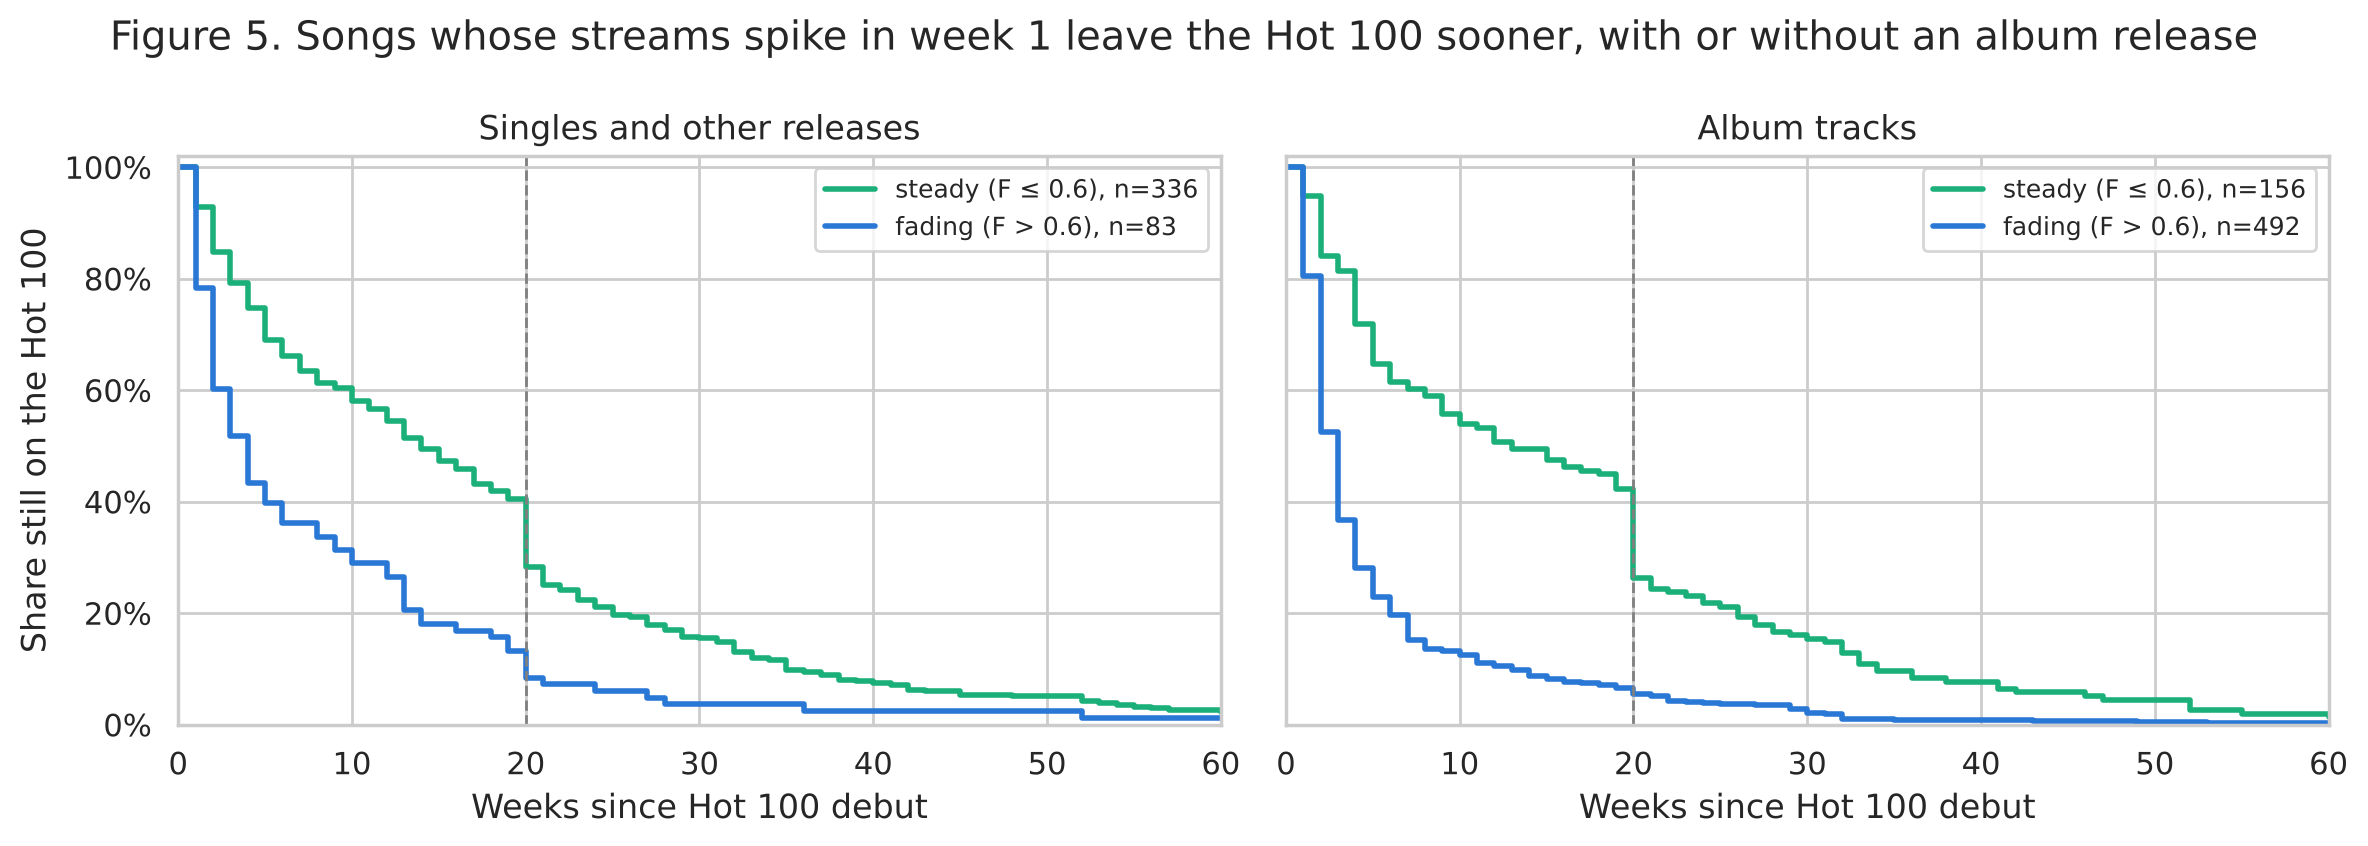

songs  median_weeks  share_long_run
release       streams                                              
album track   steady (F ≤ 0.6)    156          13.0            0.42
              fading (F > 0.6)    492           3.0            0.07
other release steady (F ≤ 0.6)    336          14.0            0.40
              fading (F > 0.6)     83           4.0            0.13

In [20]:
groups = pd.cut(h3["front_load"], [0, 0.6, 1], labels=["steady (F ≤ 0.6)", "fading (F > 0.6)"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, (album, title) in zip(axes, [(0, "Singles and other releases"), (1, "Album tracks")]):
    songs_in_panel = h3[h3["album_track"] == album]
    for (label, part), color in zip(songs_in_panel.groupby(groups.loc[songs_in_panel.index], observed=True), [GREEN, BLUE]):
        km = SurvfuncRight(part["weeks_on_chart_total"], part["finished"])
        ax.step(np.r_[0, km.surv_times], np.r_[1, km.surv_prob], where="post", color=color, linewidth=2,
                label=f"{label}, n={len(part)}")
    ax.axvline(20, color="gray", linestyle="--", linewidth=1)
    ax.set_xlim(0, 60)
    ax.set_title(title)
    ax.set_xlabel("Weeks since Hot 100 debut")
    ax.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("Share still on the Hot 100")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_ylim(0, 1.02)
fig.suptitle("Figure 5. Songs whose streams spike in week 1 leave the Hot 100 sooner, with or without an album release")
plt.tight_layout()
plt.show()

display(h3.groupby([h3["album_track"].map({0: "other release", 1: "album track"}), groups], observed=True)
          .agg(songs=("front_load", "size"), median_weeks=("weeks_on_chart_total", "median"),
               share_long_run=("long_run", "mean"))
          .round(2).rename_axis(["release", "streams"]))

**Reading Figure 5.** In both panels, the fading curve drops much faster than the steady one.
- **Other releases.** Steady songs have a median run of 14 weeks, and 40% reach 20 weeks (the dashed line). Fading songs have a median run of 4 weeks, and 13% reach 20 weeks.
- **Album tracks.** Steady album tracks have a median run of 13 weeks, and 42% reach 20 weeks, against 3 weeks and 7% for fading ones.
- **Uneven groups.** Most album tracks fade (492 of 648), and most other releases hold steady (336 of 419), which is why album status and F are hard to separate.

A steady album track lasts about as long as a steady single, so how a song's streams hold up in week 2 matters at least as much as whether it came with an album. This is the visual version of the album control above.

**Outliers and oddities.** The next cell lists the songs the model got most wrong.

In [21]:
h3["predicted_weeks"] = np.exp(ols3.fittedvalues)
cols = ["title", "artist", "first_week", "debut_rank", "album_track", "front_load", "weeks_on_chart_total", "predicted_weeks"]
print("Lasted far longer than predicted:")
display(h3.loc[ols3.resid.sort_values(ascending=False).index[:6], cols].round(2))
print("Left far sooner than predicted:")
display(h3.loc[ols3.resid.sort_values().index[:6], cols].round(2))

Lasted far longer than predicted:


,title,artist,first_week,debut_rank,album_track,front_load,weeks_on_chart_total,predicted_weeks
2253,Rock And A Hard Place,Bailey Zimmerman,2022-06-25,24,0,0.59,54,2.86
2634,Thank God,Kane Brown With Katelyn Brown,2022-09-24,22,0,0.60,42,2.36
2456,Something In The Orange,Zach Bryan,2022-05-07,55,0,0.53,66,3.94
2432,Snooze,SZA,2022-12-24,29,1,0.64,70,5.12
2737,Thought You Should Know,Morgan Wallen,2022-05-21,12,0,0.62,52,4.32
580,Cowgirls,Morgan Wallen Featuring ERNEST,2023-03-18,40,1,0.60,49,4.16


Left far sooner than predicted:


,title,artist,first_week,debut_rank,album_track,front_load,weeks_on_chart_total,predicted_weeks
3100,You're Losing Me,Taylor Swift,2023-12-09,46,0,0.38,1,30.17
1898,Noid,"Tyler, The Creator",2024-11-02,43,0,0.27,5,94.93
2106,Poland,Lil Yachty,2022-10-22,65,0,0.30,3,30.46
2422,Smeraldo Garden Marching Band,Jimin & Loco,2024-07-13,88,0,0.51,1,8.96
837,Euphoria,Kendrick Lamar,2024-05-11,11,0,0.30,17,142.45
716,Dogtooth,"Tyler, The Creator",2023-04-08,81,0,0.33,4,32.71


The misses show two things the model cannot see:
- **Radio.** Five of the six songs that lasted far longer than predicted are country songs, such as Morgan Wallen's "Thought You Should Know" (52 weeks, predicted 4), Zach Bryan's "Something In The Orange" (66 weeks, predicted 4), and Bailey Zimmerman's "Rock And A Hard Place" (54 weeks, predicted 3). The sixth is SZA's album track "Snooze" (70 weeks). Their Spotify streams faded at a normal pace (F from 0.53 to 0.64), so radio play, which Spotify data does not include, likely kept them on the Hot 100. This is the same lesson as "One Thing At A Time" in Hypothesis 1.
- **Partial first weeks.** Spotify's chart week runs Friday to Thursday. A song released midweek gets only a few days in its first chart, so its F looks low, as if its streams grew. Kendrick Lamar's "Euphoria," released on a Tuesday, has F = 0.30 and lasted 17 weeks, but the model predicted 142 weeks, longer than any run in our data. All six songs that left far sooner than predicted have low F (0.27 to 0.51), so the model overshoots for the steadiest songs.

**Lesson.** F is a strong signal for a typical song, but the straight-line model on log(weeks) should not be trusted for songs with extreme F, and it cannot see radio.

## Evaluation of significance
This section asks, for each hypothesis, whether our results could plausibly be luck. The table collects each preregistered test, plus the preregistered version of Hypothesis 3 next to our main version and the Cox check on all debuts.

**How to read the table.** Each row is one test. The *one-sided p* column is the chance of seeing a result at least this strong if there were truly no relationship. Each test only counts evidence in the direction we predicted, so its p-value is half the usual two-sided one when the estimate goes our way, and close to 1 when it goes the other way. A row says "yes" under *reject at 0.05* when p is below 0.05, and "yes" under *reject at 0.017* when it also passes our stricter bar for running three tests (0.05 / 3, the Bonferroni correction). The *estimate* column is each model's raw coefficient in its own units, so compare the yes/no columns across rows, not the estimates. Every model includes the controls from its preregistration statement (debut rank and album status for Hypotheses 1 and 2; total early streams for Hypothesis 3).

**Songs are not independent (added in Phase 3).** Songs by the same artist, especially tracks from the same album, rise and fall together, so ordinary margins of error are too small. The column *one-sided p, clustered* reruns each test with clustered standard errors, which treat all songs by the same lead artist as one group.

In [22]:
def one_sided(fit, term, predicted_sign, p2=None):
    b = fit.params[term]
    p2 = fit.pvalues[term] if p2 is None else p2
    return p2 / 2 if np.sign(b) == predicted_sign else 1 - p2 / 2

def clustered(fit, data, kind="ols"):
    # Same model, but songs by the same lead artist are treated as one group when computing margins of error
    groups = data["lead_artist"].astype("category").cat.codes
    if kind == "logit":
        return smf.logit(fit.model.formula, data=data).fit(disp=0, cov_type="cluster", cov_kwds={"groups": groups})
    return smf.ols(fit.model.formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": groups})

cox3_c = PHReg(h3_all["weeks_on_chart_total"], h3_all[["front_load", "log_streams_2wk"]].astype(float),
               status=h3_all["finished"]).fit(groups=h3_all["lead_artist"].astype("category").cat.codes.values)

tests = [  # label, model, alternative, fit, clustered fit, term, predicted sign, songs
    ("H1", "Logit, long run ~ week-2 change", "β > 0", logit1, clustered(logit1, h1, "logit"), "week2_change", +1, len(h1)),
    ("H1 (secondary)", "OLS, log weeks ~ week-2 change", "β > 0", ols1, clustered(ols1, h1), "week2_change", +1, len(h1)),
    ("H2", "OLS, log weeks ~ established", "β < 0", ols2, clustered(ols2, h2), "established", -1, len(h2)),
    ("H2 (interaction)", "OLS, established × top-20", "β < 0", ols2b, clustered(ols2b, h2), "established:top20", -1, len(h2)),
    ("H3", "OLS, log weeks ~ F (Top 200 both weeks)", "β < 0", ols3, clustered(ols3, h3), "front_load", -1, len(h3)),
    ("H3 (as preregistered)", "OLS, log weeks ~ F (0 streams if out)", "β < 0", ols3p, clustered(ols3p, h3_prereg), "front_load", -1, len(h3_prereg)),
]
rows = [(t, m, alt, fit.params[term], one_sided(fit, term, sign), one_sided(cfit, term, sign), n)
        for t, m, alt, fit, cfit, term, sign, n in tests]
rows.append(("H3 (Cox, all debuts)", "Cox, exit hazard ~ F", "log HR > 0", cox3.params[0],
             one_sided(cox3, 0, +1, cox3.pvalues[0]), one_sided(cox3_c, 0, +1, cox3_c.pvalues[0]), len(h3_all)))
sig = pd.DataFrame(rows, columns=["test", "model", "alternative", "estimate", "one-sided p", "one-sided p, clustered", "n"])
sig["reject at 0.05"] = np.where(sig["one-sided p"] < 0.05, "yes", "no")
sig["reject at 0.017"] = np.where(sig["one-sided p"] < 0.05 / 3, "yes", "no")
sig["still rejects at 0.017 when clustered"] = np.where(sig["one-sided p, clustered"] < 0.05 / 3, "yes", "no")
sig["estimate"] = sig["estimate"].round(4)
for col in ["one-sided p", "one-sided p, clustered"]:
    sig[col] = sig[col].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")
sig

,test,model,alternative,estimate,one-sided p,"one-sided p, clustered",n,reject at 0.05,reject at 0.017,still rejects at 0.017 when clustered
0,H1,"Logit, long run ~ week-2 change",β > 0,0.0623,< 0.001,< 0.001,1364,yes,yes,yes
1,H1 (secondary),"OLS, log weeks ~ week-2 change",β > 0,0.0286,< 0.001,< 0.001,1364,yes,yes,yes
2,H2,"OLS, log weeks ~ established",β < 0,-0.4186,< 0.001,< 0.001,2350,yes,yes,yes
3,H2 (interaction),"OLS, established × top-20",β < 0,0.8644,0.998,0.993,2350,no,no,no
4,H3,"OLS, log weeks ~ F (Top 200 both weeks)",β < 0,-6.7475,< 0.001,< 0.001,1067,yes,yes,yes
5,H3 (as preregistered),"OLS, log weeks ~ F (0 streams if out)",β < 0,-3.0187,< 0.001,< 0.001,1566,yes,yes,yes
6,"H3 (Cox, all debuts)","Cox, exit hazard ~ F",log HR > 0,7.5045,< 0.001,< 0.001,1254,yes,yes,yes


**Hypothesis 1: reject the null.** Week-2 movement predicts long runs (p < 0.001), far past the Bonferroni bar, and the secondary linear model agrees. The estimate is about 14 times its standard error (z ≈ 14.1), so it is very unlikely to be luck. In practical terms, a 10-spot week-2 drop multiplies the odds of a 20-week run by about 0.54 (95% CI 0.49 to 0.58), nearly halving them.

**Hypothesis 2: reject the null for the main effect.** Songs by established artists chart fewer weeks (p < 0.001), and the effect stays significant, though smaller (15% to 20% fewer weeks), under stricter definitions of an established artist. We **fail to reject** the null for the preregistered interaction: its one-sided p-value is near 1 because the estimate goes the opposite way from our prediction. Read two-sided, the interaction is significant (p = 0.004, or 0.013 with clustered errors). We report it as an unexpected finding to confirm in new data, not as a tested claim.

**Hypothesis 3: reject the null.** Front-loaded songs chart fewer weeks (p < 0.001) in our main test on 1,067 finished runs, in the preregistered 0-stream version, and in the Cox check on all debuts through 2026, all far past the Bonferroni bar. F also stays significant with an album control, among non-album songs alone, and after accounting for the week-2 drop. In practical terms, 0.1 more of a song's early streams in week 1 goes with about 49% fewer weeks on the chart (95% CI 46% to 52% fewer).

**Clustered errors (added in Phase 3).** Treating songs by the same lead artist as one group widens every margin of error, but every conclusion above holds: all the tests we reject still pass the 0.017 bar, and the H2 interaction still goes the opposite way from our prediction.

**What the p-values do not tell us:**
- **Large samples.** With 1,067 to 2,350 songs per test, even small effects can pass the significance bar. That is why we also report effect sizes and predicted chances, which show how big each effect is.
- **Songs are not independent.** Clustering by lead artist handles songs by the same artist, but songs can also move together for other reasons (the same season, the same label push), so even the clustered margins of error may be a little too small.
- **Prediction, not cause.** None of these tests shows causation. A week-2 drop is a symptom of weak demand, not its cause.

## Conclusions
**Which early signals predict a long Hot 100 run?** Within two weeks of a debut, four things tell us a lot.

1. **How the song moves in week 2 (strong, confirmed).** This is the clearest signal. Songs that hold their rank are far more likely to last 20 weeks than songs that debut at the same rank and fall.
   - For a non-album song that debuts at No. 40, holding steady gives a 56% chance of a long run.
   - A 20-spot drop lowers that to 26%.

   Adding week-2 movement to debut rank and album status makes the model explain almost four times as much about which songs last (pseudo R² from 0.063 to 0.235).
2. **Whether it came out with an album (strong).** Album tracks were the most consistent negative signal in every model. An album track that debuts at No. 40 and holds its rank has a 31% chance of a long run, against 56% for other songs (about 65% lower odds), even after accounting for debut rank and week-2 movement. A high debut driven by an album release usually means fans played the whole album once.
3. **Who the artist is (moderate, with a twist).** Established artists' songs chart about 34% fewer weeks than newer artists' songs at the same debut rank, and 15% to 20% fewer under stricter definitions of "established." The gap comes from debuts outside the top 20; among top-20 debuts, newer artists did not last longer, the opposite of what we expected.
4. **How front-loaded early streaming is (strong, confirmed).** Among 1,067 songs from 2022 to 2025 that stayed in the Spotify Top 200 for two weeks, songs whose streams spike in week 1 leave the Hot 100 sooner. At the same total early streams, 10 more percentage points of streams in week 1 goes with about half as many weeks (49% fewer). The effect shrinks but holds after accounting for album releases (43% fewer) and for the week-2 drop on Billboard (21% fewer), so how well a song keeps its listeners in week 2 adds to what the Billboard chart shows.

**Practical takeaway.** Debut rank alone is a poor guide: short and long runs debut at similar ranks (No. 44 and No. 49). Someone deciding where to put promotion after release week should look at week-2 movement, at whether the song rode in on an album, and at whether its streams held up in week 2.

## Limitations
*The first part of this section is our Phase 2 data limitations, rewritten following TA feedback to say how each one affects our results. The second part adds limitations of our Phase 3 analysis.*

- **Our Billboard source is secondhand.** A third party maintains the archive, so a scraping error would flow straight into our outcome. We found three such errors (split credits, a broken count in the last three charts, and 0 used for missing ranks) and fixed them, and our consistency checks passed for every chart from 2022 on (100 songs per chart, no shared ranks, and "last week" ranks that match the week before). We think the remaining risk is small, since an error would have to be rare enough to pass these checks. The cost of trusting only 2022 on is a shorter window of under five years.
- **Recent runs are unfinished.** 20% of 2026 Q2 debuts and 28% of Q3 debuts are still charting, and none of the Q3 debuts have reached 20 weeks yet. If we kept them as they are, they would look like quick spikes and make every signal look weaker. Hypotheses 1 and 2 therefore use songs that debuted at least 52 weeks before the latest chart (2,350 songs, only 2 still charting), and our robustness checks keep all debuts with a logistic regression on songs whose 20-week outcome is known and a Cox model. Both give the same answers, so this does not change our conclusions, but our main findings describe songs that debuted from 2022 to 2025.
- **We don't see every run from the beginning.** 193 of the 3,117 songs debuted before 2022: some were already on the chart when our window opens, and the rest are older songs that came back, such as holiday songs each December. We leave them out of every debut-based test, which is correct for a question about debuts. The bigger version of this problem was `prior_hits`, which only counted hits since 2022 and made veterans look new. Our `established` flag fixes it by looking back 3 years in the full archive.
- **Billboard's rules shape the outcome.** The 20-week rule cuts off songs below No. 50 right after 20 weeks, so 153 runs end at exactly 20 weeks against 25 at 19. Past 20 weeks, run length partly reflects the rule and not only listener interest, which makes our log(weeks) models less clean than the yes/no outcome. The 20-week cutoff avoids this, since the rule cannot remove a song before week 20. The October 2025 rule change only affects runs past 26 weeks, so it matters for the log(weeks) models and not for the cutoff. In Phase 2 we asked whether a combined chart-points score would measure success better. Such a score adds up points for each week based on rank, so it mixes how high a song charts with how long it stays. We kept weeks on the chart because our question is about how long songs last, and debut rank already captures how high they start.
- **The Spotify data is limited in several ways.**
  1. We measure streams in a song's first week on the Top 200, which may not be its release week, so for slow builders F describes the first week they were popular enough to chart. Spotify's chart week also runs Friday to Thursday, so a song released midweek gets only a few days in its first chart and looks like a grower. This is likely why the model overshoots for songs like "Euphoria."
  2. Tracks below No. 200 (1.4 to 2.7 million weekly US streams in our files, rising over the years) have no streaming data. Our main test leaves out the 499 songs (32%) that fell below that line in week 2, so it says nothing about songs that collapse that fast. The preregistered version, which counts them as 0 streams, points the same way.
  3. The data covers Spotify only. Apple Music, YouTube, sales, and radio all count toward the Hot 100 but are missing here, so F measures Spotify listeners alone. Country songs pushed to radio, like "Thought You Should Know," lasted far longer than their Spotify streams predicted.
  4. F overlaps strongly with the week-2 drop (r = −0.80), since Spotify streams are part of the Hot 100. F still adds to the week-2 drop, but its extra signal is about a third the size of its full effect, so the Billboard chart already shows most of what F tells us by week 2.
- **Matching is imperfect.** 75.5% of the 2,907 Billboard debuts that our Spotify files cover matched a Spotify track. Most unmatched songs are small (median debut No. 85, against No. 52 for matched songs), so many likely never made the Spotify Top 200, and only 22 of 868 top-40 debuts remain unmatched after we fixed accent, apostrophe, typo, and credit-style problems. A wrong match would attach the wrong streams to a song, so we keep only the 1,894 of 2,194 matches whose Billboard debut is exactly 9 days after their first Spotify week. Because the key uses only the first listed artist, two songs with the same title by the same lead artist could also be merged by mistake. Overall, Hypothesis 3 describes songs big enough to chart on Spotify, which debut higher than the average Hot 100 song.
- **Who our results could affect.** Our findings describe US charts, which are dominated by English-language pop, hip-hop, and country. Genres whose fans listen more on YouTube, on the radio, or outside the US are underrepresented, so our predictors may not hold for them. If a label or playlist curator used a model like ours to decide which songs to promote after week 2, it could pull support from slow burners like "All Mine" and from album tracks. Those songs would then last even less, which would make the model look more accurate than it is. Our `established` flag counts only lead credits, so a model like ours would also treat artists known mostly for features as newcomers.

**Phase 3 updates:** following TA feedback, we rewrote each limitation to say how it affects our results and what we did about it, and we updated the numbers for our full Spotify data (252 weeks) and our cleaning fixes.

### Limitations of our Phase 3 analysis
**Our flags are approximations.**
- **`album_track`** (3+ same-week debuts) misses albums that chart only one or two songs, and it counts short EPs, such as the 3-song sampler behind "One Thing At A Time."
- **`established`** uses the lead artist only. An artist whose earlier hits were all features counts as new, and so does a group side project such as ¥$. This matters most for the 17 newer-artist top-20 debuts that drive our surprising interaction in Hypothesis 2.

**Front-loading and album releases overlap.** Album tracks make up 86% of fading songs and 32% of steady ones in our Hypothesis 3 test. F still matters among non-album songs alone (35% fewer weeks per 0.1 of F), but album releases and fan-driven spikes are two sides of the same release-week burst, so we cannot fully separate them.

**Statistical caveats.**
- **Dependent songs.** Songs from the same album or artist rise and fall together, so ordinary margins of error are too small. We recomputed every main test with clustered standard errors, which widened the margins but changed no conclusion. Songs can also move together for reasons clustering by artist does not capture, such as the same season.
- **Multiple tests.** Our stricter Bonferroni bar covers our three main tests but not the follow-up checks, so a follow-up check is more likely to pass by luck.
- **No causal claims.** All results are associations. A week-2 drop is a symptom of weak demand, not its cause.

**The self-fulfilling risk is real in our data.** Our Phase 2 limitations warned that a model like ours could pull support from songs after week 2. Our outliers show why that matters: Morgan Wallen's "One Thing At A Time" fell 44 spots in week 2, then lasted 30 weeks after it was promoted to country radio.

## Questions for reviewers
1. **Hypothesis 2 interaction.** It came out opposite to our preregistered direction. Is reporting it as an unexpected, two-sided finding the right way to handle this? Or should we drop it until we can confirm it in new data?
2. **Which "established" definition.** Stricter definitions shrink the established-artist effect from 34% to between 15% and 20% fewer weeks. Should Phase 4 keep the preregistered flag as the main test, or switch to a stricter one?
3. **Hypothesis 3 and week 2.** F and the Billboard week-2 drop are closely related (r = −0.80), and F's effect shrinks from 49% to 21% fewer weeks per 0.1 once we add the week-2 drop. Should we present F as a separate early signal, or as an explanation of why songs drop in week 2?
4. **Week-2 sample.** Hypothesis 1 drops songs with no week-2 rank, including 134 that left in week 2 and came back later (39 of them lasted 20+ weeks). Would a two-step model (first: survives week 1? then: lasts 20 weeks?) be clearer to readers?
5. **Clustered errors.** We now treat songs by the same lead artist as one group when we compute margins of error. Would grouping by album release be better, since album tracks share one release week?

## Acknowledgements and bibliography
We thank Christian McDonald for keeping the Billboard archive public and updated each week, which made this project possible without scraping. The chart data belongs to Billboard (with data from Luminate) and Spotify.


**Data**
- Billboard. (2022–2026). *Billboard Hot 100* [weekly chart]. https://www.billboard.com/charts/hot-100/
- McDonald, C. (2026). *rwd-billboard-data* [GitHub repository, accessed Oct 14, 2026]. https://github.com/utdata/rwd-billboard-data
- Spotify. (2022–2026). *Weekly Top Songs, United States* [chart data, Jan 6, 2022 to Oct 29, 2026]. https://charts.spotify.com

**Literature**
- Askin, N., & Mauskapf, M. (2017). What makes popular culture popular? Product features and optimal differentiation in music. *American Sociological Review, 82*(5), 910–944.
- Bradlow, E. T., & Fader, P. S. (2001). A Bayesian lifetime model for the "Hot 100" Billboard songs. *Journal of the American Statistical Association, 96*(454), 368–381.
- Cantrell, L. B. (2023, May 5). Morgan Wallen nabs another MusicRow No. 1 with "One Thing At A Time." *MusicRow*. https://musicrow.com/2023/05/morgan-wallen-nabs-another-musicrow-no-1-with-one-thing-at-a-time/
- Cox, D. R. (1972). Regression models and life-tables. *Journal of the Royal Statistical Society: Series B, 34*(2), 187–220.
- Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM, 64*(12), 86–92.
- Kaplan, E. L., & Meier, P. (1958). Nonparametric estimation from incomplete observations. *Journal of the American Statistical Association, 53*(282), 457–481.
- Pessa, A. A. B., Flores, A. A., Perc, M., & Ribeiro, H. V. (2026). Charting the life of Billboard hits through memory, turnover, and predictability. *arXiv:2607.11446*.
- Salganik, M. J., Dodds, P. S., & Watts, D. J. (2006). Experimental study of inequality and unpredictability in an artificial cultural market. *Science, 311*(5762), 854–856.
- Thompson, S. (2025, October 22). After months of the same songs on the Hot 100, *Billboard* tweaks its rules. NPR.

**Software**
- Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
- Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*.
- Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272.
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.